# Stage 1 WP3 — 공식 WP2 인계 연결 및 검증

이 노트북은 팀원의 공식 WP1·WP2 산출물을 사용해 Stage 1 WP3 지식그래프 작업을 시작하는
**한국어 검토용 작업본**이다. 기존 300문서 파일럿 결과는 사용하지 않는다.

현재 범위는 1단계 교정, 2단계 품질 정책, 3단계 보정 relation 기반 최종 지식그래프 구축까지다.

1. 공식 WP2 원본을 수정하지 않고 별도 입력 폴더에서 읽는다.
2. 실제 파일명과 열 이름을 WP3 canonical contract에 연결한다.
3. 문서별 `sentence_id`를 전역 고유 `text_unit_id`로 변환한다.
4. WP1 문서 ID, relation endpoint와 evidence 문장 연결을 검증한다.
5. 최종 node type, 중복, self-loop와 sentence-local offset을 그래프 계산 전에 교정한다.
6. 교정 결과를 preparation snapshot으로 고정한다.
7. compact schema와 candidate graph 품질 등급을 적용한다.
8. Claude 1차 스크리닝을 진단하되 사람 검수로 간주하지 않는다.
9. score·co-occurrence threshold에 따른 graph metric 민감도를 비교한다.
10. 보정된 relation(Tier A+B)으로 최종 graph를 만들고 metric·community·시간 분석을 수행한다.
11. 시각화, insight 후보, graph·schema 저장과 Stage 3 smoke test로 Stage 1을 마무리한다.

분석과 팀 검토가 끝난 뒤 최종 제출본에서는 설명, 셀 제목과 주석을 영어로 바꾼다.

## 1. 공식 입력과 출력 경로

WP1 processed 데이터와 WP2 handover는 다운로드·팀 저장소의 원본을 변경하지 않고 현재 프로젝트의
Git-ignored 경로에 복사해 두었다. WP3 산출물도 파일럿 폴더와 분리된 official 경로를 사용한다.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

WP1_PROCESSED_DIR = ROOT / "dataset" / "processed"
WP2_INPUT_DIR = ROOT / "outputs" / "stage1_wp2_open_models_official_20261007"
WP3_OUTPUT_DIR = ROOT / "outputs" / "stage1_wp3_open_models_official_20261007"
CONTRACT_PATH = ROOT / "config" / "wp3_open_models_contract.json"
REVIEW_SAMPLE_PATH = (
    ROOT / "artifacts" / "stage1_wp2" / "evaluation" / "relation_review_sample_seed42.csv"
)
AI_PRESCREEN_PATH = (
    ROOT / "artifacts" / "stage1_wp2" / "evaluation" / "ai_prescreen"
    / "relation_review_claude_draft.csv"
)
PREPARATION_ARTIFACT_DIR = ROOT / "artifacts" / "stage1_wp3" / "preparation"
SENSITIVITY_ARTIFACT_DIR = ROOT / "artifacts" / "stage1_wp3" / "sensitivity"
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"

for required_path in [WP1_PROCESSED_DIR, WP2_INPUT_DIR, CONTRACT_PATH]:
    assert required_path.exists(), f"필수 입력이 없습니다: {required_path}"

ROOT, WP1_PROCESSED_DIR, WP2_INPUT_DIR, WP3_OUTPUT_DIR, CONTRACT_PATH

(WindowsPath('C:/Users/wldhg/Documents/code/computational_language'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/dataset/processed'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/outputs/stage1_wp2_open_models_official_20261007'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/outputs/stage1_wp3_open_models_official_20261007'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/config/wp3_open_models_contract.json'))

## 2. 팀 handover 파일 확인

In [2]:
expected_wp1 = [
    "corpus_clean.parquet",
    "lemma_cache.parquet",
    "open_models_core.parquet",
    "open_models_target_sentences.parquet",
    "track_scan_cache.parquet",
]
expected_wp2 = [
    "nodes.csv",
    "nodes_quarterly.csv",
    "entity_mentions.csv",
    "sentences.csv",
    "edges_relations.csv",
    "relations_evidence.csv",
    "edges_cooccurrence.csv",
    "cooccurrence_quarterly.csv",
    "schema.json",
    "data_dictionary.md",
]

handover_files = []
for work_package, directory, names in [
    ("WP1", WP1_PROCESSED_DIR, expected_wp1),
    ("WP2", WP2_INPUT_DIR, expected_wp2),
]:
    for name in names:
        path = directory / name
        handover_files.append(
            {
                "work_package": work_package,
                "file": name,
                "exists": path.exists(),
                "size_mb": round(path.stat().st_size / 1_000_000, 2) if path.exists() else None,
            }
        )

handover_table = pd.DataFrame(handover_files)
display(handover_table)
assert handover_table["exists"].all(), "공식 handover 파일이 일부 누락됐습니다."

,work_package,file,exists,size_mb
0,WP1,corpus_clean.parquet,True,250.05
1,WP1,lemma_cache.parquet,True,3.01
2,WP1,open_models_core.parquet,True,10.33
3,WP1,open_models_target_sentences.parquet,True,1.33
4,WP1,track_scan_cache.parquet,True,0.75
5,WP2,nodes.csv,True,5.08
6,WP2,nodes_quarterly.csv,True,3.98
7,WP2,entity_mentions.csv,True,25.33
8,WP2,sentences.csv,True,15.84
9,WP2,edges_relations.csv,True,3.14


WP1 대용량 Parquet과 WP2 CSV는 Git에 커밋하지 않는다. 팀 공유 저장소에는 schema, data dictionary,
최종 notebook처럼 협업과 제출에 필요한 작은 파일만 올리고, 데이터는 공유 Drive에서 관리한다.

## 3. WP2→WP3 contract 적용

In [3]:
from wp3_knowledge_graph.contract import load_contract_tables, read_contract
from wp3_knowledge_graph.pipeline import (
    annotate_final_relation_types,
    apply_compact_schema,
    apply_relation_policy,
    collapse_relations,
    correct_sentence_local_offsets,
    normalize_relation_schema,
    prepare_cooccurrence,
    prepare_entities,
    prepare_relations,
    validate_inputs,
)

contract = read_contract(CONTRACT_PATH)
tables, contract_report = load_contract_tables(WP2_INPUT_DIR, contract)

entities = prepare_entities(tables["entities"])
relations = prepare_relations(tables["relations"])
cooccurrence = prepare_cooccurrence(tables.get("cooccurrence"))
text_units = tables["text_units"]

resolved_tables = pd.DataFrame(
    [
        {
            "table": name,
            "rows": details["rows"],
            "resolved_file": Path(details["path"]).name,
            "resolved_columns": json.dumps(details["resolved_columns"], ensure_ascii=False),
        }
        for name, details in contract_report["tables"].items()
    ]
)

print("contract_version:", contract["contract_version"])
display(resolved_tables)
assert contract_report["passed"]

contract_version: wp2-to-wp3-draft-v1


,table,rows,resolved_file,resolved_columns
0,entities,54597,nodes.csv,"{""entity_id"": ""entity_id"", ""canonical_name"": ""..."
1,relations,30595,relations_evidence.csv,"{""subject_id"": ""head_id"", ""predicate"": ""relati..."
2,cooccurrence,186710,edges_cooccurrence.csv,"{""source_id"": ""entity1_id"", ""target_id"": ""enti..."
3,text_units,99438,sentences.csv,"{""document_id"": ""doc_id"", ""text"": ""sentence_te..."
4,mentions,209148,entity_mentions.csv,"{""entity_id"": ""entity_id"", ""mention_text"": ""en..."


공식 WP2 파일은 다음과 같이 선택된다.

- `nodes.csv` → canonical entities
- `relations_evidence.csv` → 문장 근거를 가진 relation assertions
- `edges_cooccurrence.csv` → co-occurrence edges
- `sentences.csv` → text units

집계본인 `edges_relations.csv`보다 `relations_evidence.csv`를 우선하는 이유는 assertion마다
`document_id`, `text_unit_id`, evidence와 발행일을 보존하기 위해서다.

## 4. WP1에서 WP2로 이어진 문서 범위 확인

In [4]:
wp1_core = pd.read_parquet(
    WP1_PROCESSED_DIR / "open_models_core.parquet",
    columns=["doc_id", "date", "title", "url"],
)
wp1_doc_ids = set(wp1_core["doc_id"].astype(str))
wp2_doc_ids = set(text_units["document_id"].astype(str))

lineage_check = pd.DataFrame(
    [
        ("WP1 핵심 문서 수", len(wp1_doc_ids)),
        ("WP2 문장 데이터에 포함된 문서 수", len(wp2_doc_ids)),
        ("WP2에서 누락된 WP1 문서 수", len(wp1_doc_ids - wp2_doc_ids)),
        ("WP1에 없지만 WP2에 추가된 문서 수", len(wp2_doc_ids - wp1_doc_ids)),
    ],
    columns=["검사항목", "개수"],
)
display(lineage_check)

assert wp1_doc_ids == wp2_doc_ids

,검사항목,개수
0,WP1 핵심 문서 수,1210
1,WP2 문장 데이터에 포함된 문서 수,1210
2,WP2에서 누락된 WP1 문서 수,0
3,WP1에 없지만 WP2에 추가된 문서 수,0


## 5. 전역 text-unit ID와 provenance 연결 확인

In [5]:
known_text_units = set(text_units["text_unit_id"].dropna().astype(str))
relation_text_units = set(relations["text_unit_id"].dropna().astype(str))
glirel_relations = relations[relations["extraction_method"] == "glirel"]
curated_relations = relations[relations["extraction_method"] == "wp1_lexicon"]

provenance_checks = pd.DataFrame(
    [
        ("text-unit ID가 모두 고유함", bool(text_units["text_unit_id"].is_unique)),
        ("relation ID가 모두 고유함", bool(relations["relation_id"].is_unique)),
        ("문장 데이터에서 찾을 수 없는 relation text unit 수", len(relation_text_units - known_text_units)),
        ("문서 ID가 없는 GLiREL relation 수", int(glirel_relations["document_id"].isna().sum())),
        ("근거 문장이 없는 GLiREL relation 수", int(glirel_relations["evidence_text"].isna().sum())),
        ("기사 근거가 없는 curated relation 수", int(curated_relations["evidence_text"].isna().sum())),
    ],
    columns=["검사항목", "결과"],
)
display(provenance_checks)

assert text_units["text_unit_id"].is_unique
assert relations["relation_id"].is_unique
assert not (relation_text_units - known_text_units)
assert glirel_relations["document_id"].notna().all()
assert glirel_relations["evidence_text"].notna().all()

,검사항목,결과
0,text-unit ID가 모두 고유함,True
1,relation ID가 모두 고유함,True
2,문장 데이터에서 찾을 수 없는 relation text unit 수,0
3,문서 ID가 없는 GLiREL relation 수,0
4,근거 문장이 없는 GLiREL relation 수,0
5,기사 근거가 없는 curated relation 수,35


WP2의 `sentence_id`는 각 문서 안에서 다시 0부터 시작한다. Contract adapter는 이를
`doc_id:sentence_id` 형식으로 변환해 전체 corpus에서 고유한 `text_unit_id`를 만든다.

`wp1_lexicon`에서 추가된 35개 `developed by` 관계는 기사 문장 근거가 없는 curated relation이다.
오류로 숨기지 않고 별도 source로 유지하며, Stage 3에서 기사 evidence가 필요한 답변에는 직접
사용하지 않는다.

## 6. 공식 산출물의 구조적 한계 재현

In [6]:
# 원본 집계 파일은 감사 목적으로만 읽으며 분석 입력으로 사용하지 않는다.
aggregated_upstream = pd.read_csv(WP2_INPUT_DIR / "edges_relations.csv")
aggregate_duplicate_rows = int(
    aggregated_upstream.duplicated(["head_id", "relation", "tail_id"]).sum()
)

wp2_schema = json.loads((WP2_INPUT_DIR / "schema.json").read_text(encoding="utf-8"))
canonical_schema = normalize_relation_schema(wp2_schema)
typed_relations = annotate_final_relation_types(entities, relations, canonical_schema)

aggregate_for_check = aggregated_upstream.rename(
    columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"}
)
typed_aggregate = annotate_final_relation_types(
    entities, aggregate_for_check, canonical_schema
)
stored_valid = typed_aggregate["type_valid"].fillna(False).astype(bool)
recommended_filter = (
    (pd.to_numeric(typed_aggregate["n_sentences"], errors="coerce").fillna(0) >= 2)
    | (typed_aggregate["source"] == "wp1_lexicon")
)

limitation_audit = pd.DataFrame(
    [
        ("원본 집계 triple의 추가 중복 행", aggregate_duplicate_rows),
        (
            "저장 당시 valid였지만 최종 node type에서는 invalid인 집계 행",
            int((stored_valid & ~typed_aggregate["final_type_valid"]).sum()),
        ),
        (
            "권장 필터 후에도 최종 node type에서 invalid인 집계 행",
            int((recommended_filter & stored_valid & ~typed_aggregate["final_type_valid"]).sum()),
        ),
        ("원본 relation assertion의 self-loop", int((relations["subject_id"] == relations["object_id"]).sum())),
        ("최종 node type에서 invalid인 relation assertion", int((~typed_relations["final_type_valid"]).sum())),
    ],
    columns=["확인 항목", "개수"],
)
display(limitation_audit)

assert aggregate_duplicate_rows == 266
assert int((stored_valid & ~typed_aggregate["final_type_valid"]).sum()) == 417
assert int((recommended_filter & stored_valid & ~typed_aggregate["final_type_valid"]).sum()) == 84
assert int((relations["subject_id"] == relations["object_id"]).sum()) == 1

,확인 항목,개수
0,원본 집계 triple의 추가 중복 행,266
1,저장 당시 valid였지만 최종 node type에서는 invalid인 집계 행,417
2,권장 필터 후에도 최종 node type에서 invalid인 집계 행,84
3,원본 relation assertion의 self-loop,1
4,최종 node type에서 invalid인 relation assertion,11435


위 수치는 노트북 미실행 때문에 생긴 것이 아니라 WP2의 집계 기준과 mention 단계 type을 사용한
검증 방식에서 생긴다. 따라서 WP2 원본 파일을 고쳐 쓰지 않고, 아래에서 최종 node type을 적용한
WP3 분석용 relation view를 새로 만든다.

## 7. 그래프 계산 전 relation 교정

In [7]:
analysis_relations, relation_policy_audit = apply_relation_policy(
    typed_relations,
    reviews=None,
    policies=contract["policies"],
)
collapsed_relations = collapse_relations(analysis_relations, documents=None)

relation_correction_summary = pd.DataFrame(
    [
        ("원본 relation assertion", len(relations)),
        ("self-loop 제외", relation_policy_audit.get("excluded_self_relations", 0)),
        ("최종 node type signature 불일치 제외", relation_policy_audit.get("excluded_by_final_signature", 0)),
        ("분석용 relation assertion", len(analysis_relations)),
        ("triple 기준으로 collapse한 분석용 edge", len(collapsed_relations)),
        (
            "collapsed edge의 추가 중복",
            int(collapsed_relations.duplicated(["subject_id", "predicate", "object_id"]).sum()),
        ),
    ],
    columns=["교정 단계", "개수"],
)
display(relation_correction_summary)

assert analysis_relations["final_type_valid"].all()
assert not (analysis_relations["subject_id"] == analysis_relations["object_id"]).any()
assert not collapsed_relations.duplicated(["subject_id", "predicate", "object_id"]).any()

,교정 단계,개수
0,원본 relation assertion,30595
1,self-loop 제외,1
2,최종 node type signature 불일치 제외,11434
3,분석용 relation assertion,19160
4,triple 기준으로 collapse한 분석용 edge,13322
5,collapsed edge의 추가 중복,0


여기서 제거되는 것은 원본 evidence가 아니라 **분석용 그래프에 포함할지 여부**다.
`relations_evidence.csv`는 그대로 보존하며, 분석용 assertion에는 최종 node type 기준으로 유효한
관계만 포함한다. 동일 triple의 여러 문장 근거는 `collapsed_relations`의 evidence 집계에 보존된다.

## 8. Sentence-local mention offset 교정

In [8]:
corrected_mentions = correct_sentence_local_offsets(tables["mentions"], text_units)
offset_summary = (
    corrected_mentions["offset_status"]
    .value_counts(dropna=False)
    .rename_axis("교정 상태")
    .reset_index(name="mention 수")
)
display(offset_summary)
display(
    corrected_mentions.loc[
        ~corrected_mentions["offset_resolved"],
        ["entity_id", "mention_text", "text_unit_id", "sentence_text"],
    ]
)

resolved_mentions = corrected_mentions[corrected_mentions["offset_resolved"]]
resolved_span_text = resolved_mentions.apply(
    lambda row: row["sentence_text"][
        int(row["sentence_local_start"]):int(row["sentence_local_end"])
    ],
    axis=1,
)
resolved_span_matches = (
    resolved_span_text.str.casefold().to_numpy()
    == resolved_mentions["mention_text"].str.casefold().to_numpy()
).all()
assert resolved_span_matches
assert int((~corrected_mentions["offset_resolved"]).sum()) == 2

,교정 상태,mention 수
0,already_valid,196171
1,corrected_unique,10624
2,corrected_nearest,2351
3,unresolved,2


,entity_id,mention_text,text_unit_id,sentence_text
70352,concept:open_source_model,open source AI. A popular model,doc_56678eac5d:22,”\r\n\r\nWhen working with the open source com...
98353,concept:open_source_model,open-source licenses. Models,doc_76edd77dd8:78,Several LLMs are free under open-source licenses.


기사 전체 기준 `article_start_char`와 `article_end_char`는 수정하지 않는다. 별도
`sentence_local_start`·`sentence_local_end`를 추가했으며, 12,975개 mismatch를 자동 교정했다.
문장 하나의 범위를 넘어선 잘못된 mention 2개는 자동 교정하지 않고 `unresolved`로 격리한다.
Stage 3에서 정확한 span 강조가 필요할 때는 `offset_resolved=True`인 행만 사용한다.

## 9. 교정 후 구조 무결성 검사

In [9]:
validation = validate_inputs(
    entities,
    analysis_relations,
    cooccurrence,
    schema=canonical_schema,
    policies=contract["policies"],
)

validation_labels = {
    "duplicate_entity_ids": "중복 entity ID 수",
    "duplicate_relation_ids": "중복 relation ID 수",
    "null_entity_keys": "필수 key가 비어 있는 entity 수",
    "null_relation_keys": "필수 key가 비어 있는 relation 수",
    "dangling_relation_subjects": "존재하지 않는 subject를 참조하는 relation 수",
    "dangling_relation_objects": "존재하지 않는 object를 참조하는 relation 수",
    "self_relations": "self-loop 수",
    "invalid_relation_signatures": "최종 schema signature 위반 수",
    "dangling_cooccurrence_endpoints": "존재하지 않는 endpoint를 참조하는 공동출현 edge 수",
}
validation_table = pd.DataFrame(
    [
        {"검사항목": validation_labels.get(key, key), "결과": value}
        for key, value in validation.items()
        if key not in {"errors", "warnings", "passed", "missing_relation_provenance"}
    ]
)
display(validation_table)
print("근거 정보가 없는 relation 수:", validation["missing_relation_provenance"])
print("경고:", validation["warnings"])
print("오류:", validation["errors"])

assert validation["passed"], validation["errors"]

,검사항목,결과
0,중복 entity ID 수,0
1,중복 relation ID 수,0
2,필수 key가 비어 있는 entity 수,0
3,필수 key가 비어 있는 relation 수,0
4,존재하지 않는 subject를 참조하는 relation 수,0
5,존재하지 않는 object를 참조하는 relation 수,0
6,self-loop 수,0
7,최종 schema signature 위반 수,0
8,존재하지 않는 endpoint를 참조하는 공동출현 edge 수,0


근거 정보가 없는 relation 수: {'document_id': 28, 'text_unit_id': 28, 'evidence_text': 28}
경고: ["missing_relation_provenance={'document_id': 28, 'text_unit_id': 28, 'evidence_text': 28}"]
오류: []


교정 후에는 schema 불일치, self-loop와 triple 중복이 분석용 relation에 남지 않는다. 원본의
curated `wp1_lexicon` relation 35개 중 최종 type·self-loop 정책을 통과한 28개는 기사 근거가 없어
경고로 남는다. 이들은 source를 구분해 보존하되 기사 evidence가 필요한 Stage 3 답변에는 직접
사용하지 않는다.

## 10. 공식 schema의 현재 범위

In [10]:
wp2_schema = json.loads((WP2_INPUT_DIR / "schema.json").read_text(encoding="utf-8"))
entity_types = wp2_schema["node"]["entity_types"]
relation_types = wp2_schema["edges"]["relation"]["types"]

schema_summary = pd.DataFrame(
    [
        ("엔티티 유형", len(entity_types)),
        ("관계 유형", len(relation_types)),
        ("노드", len(entities)),
        ("원본 관계 assertion", len(relations)),
        ("교정 후 분석용 관계 assertion", len(analysis_relations)),
        ("교정 후 collapsed relation", len(collapsed_relations)),
        ("공동출현 edge", len(cooccurrence)),
        ("text unit", len(text_units)),
    ],
    columns=["항목", "개수"],
)
display(schema_summary)

display(pd.DataFrame(
    [
        {
            "relation": name,
            "head_types": ", ".join(spec["head_types"]),
            "tail_types": ", ".join(spec["tail_types"]),
        }
        for name, spec in relation_types.items()
    ]
))

,항목,개수
0,엔티티 유형,20
1,관계 유형,36
2,노드,54597
3,원본 관계 assertion,30595
4,교정 후 분석용 관계 assertion,19160
5,교정 후 collapsed relation,13322
6,공동출현 edge,186710
7,text unit,99438


,relation,head_types,tail_types
0,developed by,"FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG...","ORG, COMPANY, PERSON"
1,released by,"FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG...","ORG, COMPANY, PERSON"
2,announced by,"FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG...","ORG, COMPANY, PERSON"
3,member of family,"FOUNDATION_MODEL, AI_MODEL","FOUNDATION_MODEL, AI_MODEL"
4,successor of,"FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG...","FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG..."
5,based on,"FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG...","FOUNDATION_MODEL, AI_MODEL, PRODUCT, TECHNOLOG..."
6,fine-tuned from,"FOUNDATION_MODEL, AI_MODEL","FOUNDATION_MODEL, AI_MODEL"
7,distilled from,"FOUNDATION_MODEL, AI_MODEL","FOUNDATION_MODEL, AI_MODEL"
8,quantized version of,"FOUNDATION_MODEL, AI_MODEL","FOUNDATION_MODEL, AI_MODEL"
9,has parameter count,"FOUNDATION_MODEL, AI_MODEL, ARCHITECTURE",MODEL_SPEC


20개 entity type과 36개 relation type은 extraction recall을 위한 넓은 schema다. 과제에서 요구하는
compact topic-specific schema를 만들기 위해 다음 단계에서 원본 label을 보존하면서 분석용
canonical type과 predicate를 별도로 정의한다.

## 11. 교정된 실제 데이터 미리보기

In [11]:
display(entities.sort_values("mention_count", ascending=False).head(15))
display(
    analysis_relations[
        [
            "subject_id", "predicate", "object_id", "document_id",
            "text_unit_id", "evidence_text", "published_at",
            "extraction_method", "rule_score",
        ]
    ].head(15)
)
display(cooccurrence.sort_values("sentence_count", ascending=False).head(15))
display(collapsed_relations.head(15))

,entity_id,canonical_name,entity_type,canonical_id,developer,model_versions,mention_count,document_count,n_sentences,first_seen,last_seen,sources
1833,technology:ai,AI,TECHNOLOGY,NaN,NaN,NaN,7630,995,6905,2024-09-13,2026-08-31,gliner+spacy
7640,org:deepseek,DeepSeek,COMPANY,deepseek,DeepSeek,"DeepSeek R1, DeepSeek R2, DeepSeek V1, DeepSee...",4560,566,4197,2024-10-11,2026-08-31,domain_dict+gliner+spacy
16198,org:nvidia,NVIDIA,COMPANY,NaN,NaN,NaN,3494,471,2876,2024-09-13,2026-08-27,gliner+spacy
40752,model:model,model,AI_MODEL,NaN,NaN,NaN,3283,696,2869,2024-09-12,2026-08-26,gliner+spacy
52873,place:united_states,united_states,GPE,NaN,NaN,NaN,2446,444,2242,2024-09-26,2026-08-31,gliner+spacy
39187,model:llm,llm,AI_MODEL,NaN,NaN,NaN,2404,594,2154,2024-09-12,2026-08-26,gliner+spacy
17400,org:openai,OpenAI,COMPANY,NaN,NaN,NaN,2313,632,2171,2024-09-12,2026-08-27,gliner+spacy
14196,model:llama,Llama,FOUNDATION_MODEL,llama,Meta,"Llama 1, Llama 2, Llama 2.0, Llama 3, Llama 3....",2035,432,1811,2024-09-12,2026-08-12,domain_dict+gliner+spacy
6044,place:china,China,GPE,NaN,NaN,NaN,1977,344,1873,2024-10-11,2026-08-31,gliner+spacy
10671,org:google,Google,COMPANY,NaN,NaN,NaN,1953,542,1776,2024-09-12,2026-08-31,gliner+spacy


,subject_id,predicate,object_id,document_id,text_unit_id,evidence_text,published_at,extraction_method,rule_score
0,technology:ai,developed by,org:anthropic,doc_b2d9110022,doc_b2d9110022:215,Claude can now use your computer (Activity: 21...,2026-03-25,glirel,0.988362
1,model:claude,developed by,org:anthropic,doc_b2d9110022,doc_b2d9110022:215,Claude can now use your computer (Activity: 21...,2026-03-25,glirel,0.987690
2,hardware:computer,developed by,org:anthropic,doc_b2d9110022,doc_b2d9110022:215,Claude can now use your computer (Activity: 21...,2026-03-25,glirel,0.976158
3,platform:gemini,developed by,org:deepmind,doc_bbcaf11fa1,doc_bbcaf11fa1:109,Gemini is Google’s latest family of LLMs (succ...,2025-07-13,glirel,0.975896
4,product:dall_e_2,developed by,org:openai,doc_8584839ac2,doc_8584839ac2:7,"DALL-E 2 - Developed by OpenAI, this model dem...",2025-04-03,glirel,0.975281
5,model:hermes,developed by,org:nous_research,doc_f25b295200,doc_f25b295200:3,"Developed by Nous Research, Hermes is designed...",2026-05-13,glirel,0.974308
6,product:muse_series,developed by,org:meta_superintelligence_labs,doc_9a4e87cb64,doc_9a4e87cb64:1,Dubbed Muse Spark and originally code-named Av...,2026-04-08,glirel,0.972101
7,model:opus,developed by,org:anthropic,doc_31442c1027,doc_31442c1027:19,"Developed by Anthropic, the Claude series (inc...",2025-03-28,glirel,0.971235
8,model:muse_spark,developed by,org:meta_superintelligence_labs,doc_9a4e87cb64,doc_9a4e87cb64:1,Dubbed Muse Spark and originally code-named Av...,2026-04-08,glirel,0.971182
9,model:sonnet,developed by,org:anthropic,doc_31442c1027,doc_31442c1027:19,"Developed by Anthropic, the Claude series (inc...",2025-03-28,glirel,0.970981


,source_id,target_id,entity1,type1,entity2,type2,sentence_count,document_count,npmi,main_relation,relation_sentences,first_seen,last_seen
0,place:china,place:united_states,China,GPE,united_states,GPE,599,279,0.519,NaN,0,2024-10-11,2026-08-31
1,technology:ai,org:deepseek,AI,TECHNOLOGY,DeepSeek,FOUNDATION_MODEL,441,512,0.076,AI -[developed by]-> DeepSeek,94,2025-01-08,2026-08-11
2,technology:ai,place:united_states,AI,TECHNOLOGY,united_states,GPE,434,427,0.189,NaN,0,2024-10-11,2026-08-31
3,technology:ai,org:nvidia,AI,TECHNOLOGY,NVIDIA,COMPANY,428,423,0.140,AI -[developed by]-> NVIDIA,169,2024-09-13,2026-08-11
4,model:llama,org:meta,Llama,FOUNDATION_MODEL,Meta,COMPANY,410,247,0.527,Llama -[developed by]-> Meta,215,2024-09-13,2026-08-12
5,org:deepseek,place:united_states,DeepSeek,FOUNDATION_MODEL,united_states,GPE,352,310,0.233,DeepSeek -[headquartered in]-> united_states,4,2025-01-08,2026-08-04
6,org:deepseek,org:openai,DeepSeek,FOUNDATION_MODEL,OpenAI,COMPANY,352,407,0.238,DeepSeek -[competes with]-> OpenAI,166,2024-11-27,2026-08-11
7,place:china,org:deepseek,China,GPE,DeepSeek,FOUNDATION_MODEL,342,292,0.258,DeepSeek -[headquartered in]-> China,37,2025-01-13,2026-08-11
8,technology:ai,place:china,AI,TECHNOLOGY,China,GPE,329,330,0.162,NaN,0,2024-10-28,2026-08-31
9,org:anthropic,org:openai,Anthropic,COMPANY,OpenAI,COMPANY,306,306,0.477,OpenAI -[competes with]-> Anthropic,119,2024-09-25,2026-08-27


,edge_id,subject_id,predicate,object_id,evidence_count,document_count,domain_count,first_seen,last_seen,asserted_count,negated_count,uncertain_count,mean_rule_score,max_rule_score,relation_ids,document_ids,text_unit_ids,domains
0,edge:7e6b97bad287197b,hardware:a100,acquired by,org:high_flyer_2,2,2,0,2025-01-28,2025-05-30,2,0,0,0.709284,0.732572,"[""relation:06af4ca50449e4f0"", ""relation:4083eb...","[""doc_3ac75461e8"", ""doc_e983706247""]","[""doc_3ac75461e8:2"", ""doc_e983706247:27""]",[]
1,edge:bc573e53b67c7100,hardware:a100,acquired by,org:nvidia,1,1,0,2025-01-28,2025-01-28,1,0,0,0.521872,0.521872,"[""relation:f96b600be37e7875""]","[""doc_e983706247""]","[""doc_e983706247:27""]",[]
2,edge:d11757622484ba35,hardware:computer_chips,acquired by,org:nvidia,1,1,0,2025-07-11,2025-07-11,1,0,0,0.598173,0.598173,"[""relation:d6e382b2f0d4db71""]","[""doc_0e507bce88""]","[""doc_0e507bce88:15""]",[]
3,edge:31d3609091fe5a1b,hardware:cpu,acquired by,org:rivos,1,1,0,2026-01-22,2026-01-22,1,0,0,0.858296,0.858296,"[""relation:6f88eedd4b7ae871""]","[""doc_c925a6822f""]","[""doc_c925a6822f:39""]",[]
4,edge:9809cebaf8cc7ebe,hardware:datacenter_gpus,acquired by,org:nvidia,1,1,0,2025-04-30,2025-04-30,1,0,0,0.667653,0.667653,"[""relation:96ed7071ad28cfd2""]","[""doc_d1cacbe004""]","[""doc_d1cacbe004:63""]",[]
5,edge:6ac736c16d2b3445,hardware:datacenters,acquired by,org:meta_compute_organization,1,1,0,2026-01-22,2026-01-22,1,0,0,0.519763,0.519763,"[""relation:8cc8c44d5c8623d4""]","[""doc_c925a6822f""]","[""doc_c925a6822f:20""]",[]
6,edge:ba68e17f8e2c943d,hardware:dgx_station,acquired by,org:coreweave,1,1,0,2026-03-11,2026-03-11,1,0,0,0.775259,0.775259,"[""relation:d0df8290c091e40e""]","[""doc_7f7f8e5fdc""]","[""doc_7f7f8e5fdc:118""]",[]
7,edge:0f12d4b5ed7d3d90,hardware:gpu,acquired by,org:coreweave,1,1,0,2026-04-04,2026-04-04,1,0,0,0.525457,0.525457,"[""relation:f961c5485faa52ea""]","[""doc_399b320253""]","[""doc_399b320253:8""]",[]
8,edge:eec2178f9f1933f2,hardware:gpu,acquired by,org:nvidia,1,1,0,2026-04-04,2026-04-04,1,0,0,0.512114,0.512114,"[""relation:39a6498842c9497c""]","[""doc_399b320253""]","[""doc_399b320253:8""]",[]
9,edge:a56482de426eb898,hardware:gpu,acquired by,org:rivos,1,1,0,2026-01-22,2026-01-22,1,0,0,0.861094,0.861094,"[""relation:378da00f88813f16""]","[""doc_c925a6822f""]","[""doc_c925a6822f:39""]",[]


## 12. 수동 relation 검수 준비 상태

In [12]:
assert REVIEW_SAMPLE_PATH.exists(), f"검수 표본이 없습니다: {REVIEW_SAMPLE_PATH}"
review_sample = pd.read_csv(REVIEW_SAMPLE_PATH)

review_status = pd.DataFrame(
    [
        ("표본 행 수", len(review_sample)),
        ("표본에 포함된 관계 유형 수", review_sample["predicate"].nunique()),
        ("검수자 배정 수", review_sample["reviewer_assignment"].nunique()),
        ("검수가 완료된 행 수", review_sample["review_correct"].notna().sum()),
    ],
    columns=["항목", "개수"],
)
display(review_status)
display(review_sample["reviewer_assignment"].value_counts().rename("rows"))

,항목,개수
0,표본 행 수,90
1,표본에 포함된 관계 유형 수,26
2,검수자 배정 수,3
3,검수가 완료된 행 수,0


reviewer_assignment
Reviewer_A    30
Reviewer_B    30
Reviewer_C    30
Name: rows, dtype: int64

검수 표본은 90개 unique GLiREL triple이며 세 명에게 30개씩 배정되어 있다. 현재는 검수 전 상태다.
팀원은 추출된 열을 수정하지 않고 `review_correct`, `reviewer`, `review_error_type`, `review_notes`만
작성한다.

## 13. WP3 1단계 완료 판정

In [13]:
step1_checks = pd.DataFrame(
    [
        ("공식 WP1 파일이 모두 있음", handover_table.query("work_package == 'WP1'")["exists"].all()),
        ("공식 WP2 파일이 모두 있음", handover_table.query("work_package == 'WP2'")["exists"].all()),
        ("계약이 공식 WP2 파일을 올바르게 선택함", contract_report["passed"]),
        ("WP1과 WP2의 문서 ID 집합이 일치함", wp1_doc_ids == wp2_doc_ids),
        ("text-unit ID가 전체 데이터에서 고유함", text_units["text_unit_id"].is_unique),
        ("GLiREL 근거가 text unit에 연결됨", not (relation_text_units - known_text_units)),
        ("최종 node type 기준으로 모든 분석용 relation이 유효함", analysis_relations["final_type_valid"].all()),
        ("분석용 relation에 self-loop가 없음", not (analysis_relations["subject_id"] == analysis_relations["object_id"]).any()),
        ("collapsed relation에 중복 triple이 없음", not collapsed_relations.duplicated(["subject_id", "predicate", "object_id"]).any()),
        ("교정 가능한 sentence-local offset이 모두 일치함", resolved_span_matches),
        ("자동 교정 불가능한 mention 2개가 격리됨", int((~corrected_mentions["offset_resolved"]).sum()) == 2),
        ("교정 후 엔티티와 edge 구조가 유효함", validation["passed"]),
        ("수동 검수 표본 90개가 준비됨", len(review_sample) == 90),
    ],
    columns=["완료 기준", "통과"],
)
display(step1_checks)
assert step1_checks["통과"].all()
print("WP3 1단계 완료: WP1·WP2 원본을 수정하지 않고 공식 인계 산출물을 연결했습니다.")

,완료 기준,통과
0,공식 WP1 파일이 모두 있음,True
1,공식 WP2 파일이 모두 있음,True
2,계약이 공식 WP2 파일을 올바르게 선택함,True
3,WP1과 WP2의 문서 ID 집합이 일치함,True
4,text-unit ID가 전체 데이터에서 고유함,True
5,GLiREL 근거가 text unit에 연결됨,True
6,최종 node type 기준으로 모든 분석용 relation이 유효함,True
7,분석용 relation에 self-loop가 없음,True
8,collapsed relation에 중복 triple이 없음,True
9,교정 가능한 sentence-local offset이 모두 일치함,True


WP3 1단계 완료: WP1·WP2 원본을 수정하지 않고 공식 인계 산출물을 연결했습니다.


# WP3 2단계 — Compact schema와 relation 품질 정책

1단계의 교정 결과를 별도 preparation snapshot으로 저장한 뒤 compact 분석 schema를 적용한다.
원본 type과 predicate는 삭제하지 않으며, 상위 그룹은 전체 구조를 요약할 때만 사용한다.

## 14. Compact schema 적용

In [14]:
assert COMPACT_SCHEMA_PATH.exists()
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))
compact_entities, compact_analysis_relations = apply_compact_schema(
    entities, analysis_relations, compact_schema
)

compact_schema_summary = pd.DataFrame(
    [
        ("원본 entity type", entities["entity_type"].nunique()),
        ("compact entity type", compact_entities["entity_type_compact"].nunique()),
        ("WP2 schema relation type", len(compact_schema["predicate_group_mapping"])),
        ("분석용 assertion에 남은 원본 relation type", analysis_relations["predicate"].nunique()),
        ("compact predicate group", compact_analysis_relations["predicate_group"].nunique()),
    ],
    columns=["항목", "개수"],
)
display(compact_schema_summary)
display(
    compact_analysis_relations["predicate_group"]
    .value_counts()
    .rename_axis("predicate group")
    .reset_index(name="assertion 수")
)

assert compact_entities["raw_entity_type"].equals(compact_entities["entity_type"])
assert compact_analysis_relations["raw_predicate"].equals(
    compact_analysis_relations["predicate"]
)
assert compact_entities["entity_type_compact"].notna().all()
assert compact_analysis_relations["predicate_group"].notna().all()

,항목,개수
0,원본 entity type,20
1,compact entity type,9
2,WP2 schema relation type,36
3,분석용 assertion에 남은 원본 relation type,31
4,compact predicate group,8


,predicate group,assertion 수
0,PROVENANCE,9804
1,EVALUATION,4086
2,ORGANIZATION_RELATION,3213
3,DEPLOYMENT,1686
4,GOVERNANCE_RELATION,181
5,ATTRIBUTE,128
6,LINEAGE,48
7,TRAINING,14


compact mapping은 20개 entity type을 9개 분석 그룹으로, 36개 relation type을 8개 상위 그룹으로
정리한다. `raw_entity_type`과 `raw_predicate`가 보존되므로 Graph-RAG와 세부 relation 분석에서는
원래 의미를 다시 사용할 수 있다. 상위 그룹만으로 사실 관계를 해석해서는 안 된다.

## 15. Preparation snapshot 확인

In [15]:
manifest_path = PREPARATION_ARTIFACT_DIR / "preparation_manifest.json"
policy_audit_path = PREPARATION_ARTIFACT_DIR / "policy_audit.json"
assert manifest_path.exists() and policy_audit_path.exists()

preparation_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
policy_audit = json.loads(policy_audit_path.read_text(encoding="utf-8"))
display(
    pd.DataFrame(
        preparation_manifest["counts"].items(),
        columns=["snapshot 항목", "개수"],
    )
)
display(
    pd.DataFrame(
        policy_audit["quality_tiers_in_candidate_graph"].items(),
        columns=["candidate quality tier", "relation assertion 수"],
    )
)

assert preparation_manifest["status"] == "candidate_graph_only_pending_human_relation_review"
assert preparation_manifest["counts"]["candidate_relation_assertions"] == len(analysis_relations)
assert policy_audit["human_validated_relations"] == 0
assert not policy_audit["ai_prescreen_used_as_exclusion_policy"]

,snapshot 항목,개수
0,nodes,54597
1,raw_relation_assertions,30595
2,candidate_relation_assertions,19160
3,collapsed_candidate_edges,13322
4,unresolved_mentions,2


,candidate quality tier,relation assertion 수
0,curated_without_article_evidence,28
1,high_score_candidate,1766
2,low_score_candidate,9557
3,medium_score_candidate,7809


## 16. Claude 1차 스크리닝 결과

In [16]:
assert AI_PRESCREEN_PATH.exists()
ai_prescreen = pd.read_csv(AI_PRESCREEN_PATH)
labels = ai_prescreen["review_correct"].str.upper()
decided = labels.isin(["TRUE", "FALSE"])
ai_precision = labels.eq("TRUE").sum() / decided.sum()

score_review = (
    ai_prescreen.assign(_label=labels)
    .groupby("score_band")["_label"]
    .value_counts()
    .unstack(fill_value=0)
)
for required_label in ["TRUE", "FALSE", "AMBIGUOUS"]:
    if required_label not in score_review.columns:
        score_review[required_label] = 0
score_review["precision"] = score_review["TRUE"] / (
    score_review["TRUE"] + score_review["FALSE"]
)
display(score_review[["TRUE", "FALSE", "AMBIGUOUS", "precision"]])

review_decision = pd.DataFrame(
    [
        ("AI가 판정한 표본", len(ai_prescreen)),
        ("TRUE", int(labels.eq("TRUE").sum())),
        ("FALSE", int(labels.eq("FALSE").sum())),
        ("AMBIGUOUS", int(labels.eq("AMBIGUOUS").sum())),
        ("모호 항목 제외 precision", round(ai_precision, 3)),
        ("목표 precision", 0.8),
    ],
    columns=["항목", "값"],
)
display(review_decision)

assert set(ai_prescreen["relation_id"]) == set(review_sample["relation_id"])
assert ai_precision < 0.8

_label,TRUE,FALSE,AMBIGUOUS,precision
score_band,,,,
0.50-0.59,11,24,5,0.314286
0.60-0.74,24,19,2,0.558140
0.75-1.00,4,1,0,0.800000


,항목,값
0,AI가 판정한 표본,90.00
1,TRUE,39.00
2,FALSE,44.00
3,AMBIGUOUS,7.00
4,모호 항목 제외 precision,0.47
5,목표 precision,0.80


Claude 결과는 원본 필드를 유지한 완전한 1차 스크리닝이지만 공식 수동 검수로 사용하지 않는다.
현재 0.470 precision은 raw relation을 신뢰 가능한 사실 그래프로 제시할 수 없다는 강한 경고다.
반면 이 값만으로 전체 triple을 삭제할 수도 없다. 표본은 triple마다 evidence 문장 하나만 보여 주기
때문에, 다른 문장에 실제 근거가 있을 가능성이 있기 때문이다.

따라서 현재 허용되는 작업과 금지되는 작업을 구분한다.

- 가능: candidate graph의 compact schema, 분포와 탐색적 구조 분석
- 가능: FALSE·AMBIGUOUS 사례를 우선순위로 한 사람의 재검수
- 불가: AI label을 이용한 전체 edge 자동 삭제
- 불가: candidate graph를 검증된 사실 지식그래프로 표현
- 불가: 사람 검수 전 relation edge만으로 Stage 3 답변을 뒷받침

## 17. Candidate relation graph 민감도

In [17]:
required_sensitivity_files = [
    "relation_variant_summary.csv",
    "relation_variant_stability.csv",
    "relation_top_nodes.csv",
    "cooccurrence_threshold_summary.csv",
]
for filename in required_sensitivity_files:
    assert (SENSITIVITY_ARTIFACT_DIR / filename).exists(), filename

relation_variant_summary = pd.read_csv(
    SENSITIVITY_ARTIFACT_DIR / "relation_variant_summary.csv"
)
relation_stability = pd.read_csv(
    SENSITIVITY_ARTIFACT_DIR / "relation_variant_stability.csv"
)
relation_top_nodes = pd.read_csv(
    SENSITIVITY_ARTIFACT_DIR / "relation_top_nodes.csv"
)

display(relation_variant_summary)
display(
    relation_top_nodes[relation_top_nodes["rank"] <= 10][
        ["variant", "rank", "canonical_name", "entity_type_compact", "pagerank"]
    ]
)

assert set(relation_variant_summary["validation_status"]) == {
    "candidate_pending_human_validation"
}

,variant,description,assertion_count,collapsed_edge_count,node_count,predicate_count,predicate_group_count,component_count,largest_component_nodes,largest_component_share,density,validation_status
0,all_candidates,All structurally valid relation candidates.,19160,13322,8331,31,8,600,6701,0.804345,0.000192,candidate_pending_human_validation
1,medium_plus,GLiREL relation candidates with score >= 0.60.,9575,6747,4800,28,7,468,3579,0.745625,0.000293,candidate_pending_human_validation
2,high_score,GLiREL relation candidates with score >= 0.75.,1766,1458,1323,18,5,225,764,0.577475,0.000834,candidate_pending_human_validation


,variant,rank,canonical_name,entity_type_compact,pagerank
0,all_candidates,1,Google,ORGANIZATION,0.045032
1,all_candidates,2,NVIDIA,ORGANIZATION,0.044431
2,all_candidates,3,OpenAI,ORGANIZATION,0.036959
3,all_candidates,4,Anthropic,ORGANIZATION,0.024897
4,all_candidates,5,Microsoft,ORGANIZATION,0.023989
5,all_candidates,6,Amazon,ORGANIZATION,0.017992
6,all_candidates,7,Meta,ORGANIZATION,0.015762
7,all_candidates,8,DeepSeek,ORGANIZATION,0.015724
8,all_candidates,9,united_states,LOCATION_OR_GROUP,0.011265
9,all_candidates,10,Apple,ORGANIZATION,0.009419


`all_candidates`, `medium_plus`, `high_score`는 각각 19,160개, 9,575개, 1,766개 assertion을
사용한다. score threshold가 높아질수록 graph 크기와 연결 구조가 크게 줄어든다. 이 비교는
confidence 선택에 따른 민감도를 보여 줄 뿐, 높은 score가 사람 검수 정확성을 보장하지 않는다.

## 18. PageRank 순위 안정성

,variant_a,variant_b,top20_jaccard,pagerank_spearman
1,all_candidates,medium_plus,0.739130,0.395473
2,all_candidates,high_score,0.379310,0.188925
3,medium_plus,all_candidates,0.739130,0.395473
5,medium_plus,high_score,0.481481,0.243096
6,high_score,all_candidates,0.379310,0.188925
7,high_score,medium_plus,0.481481,0.243096


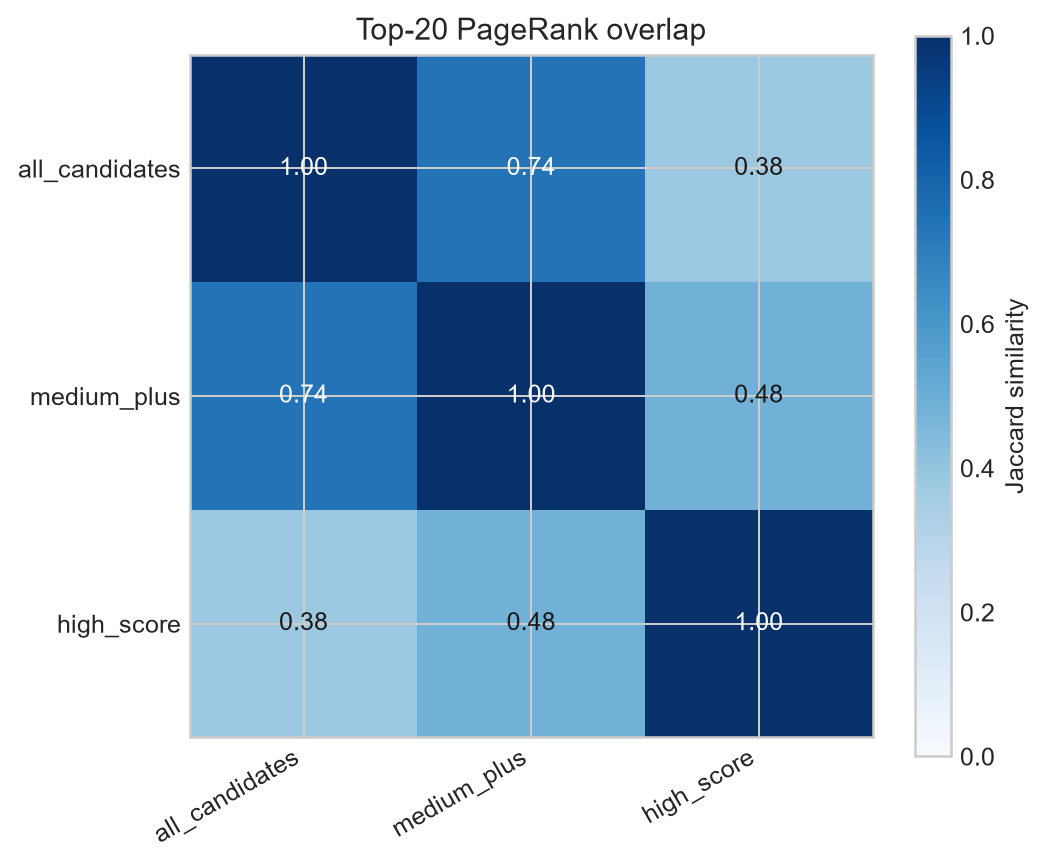

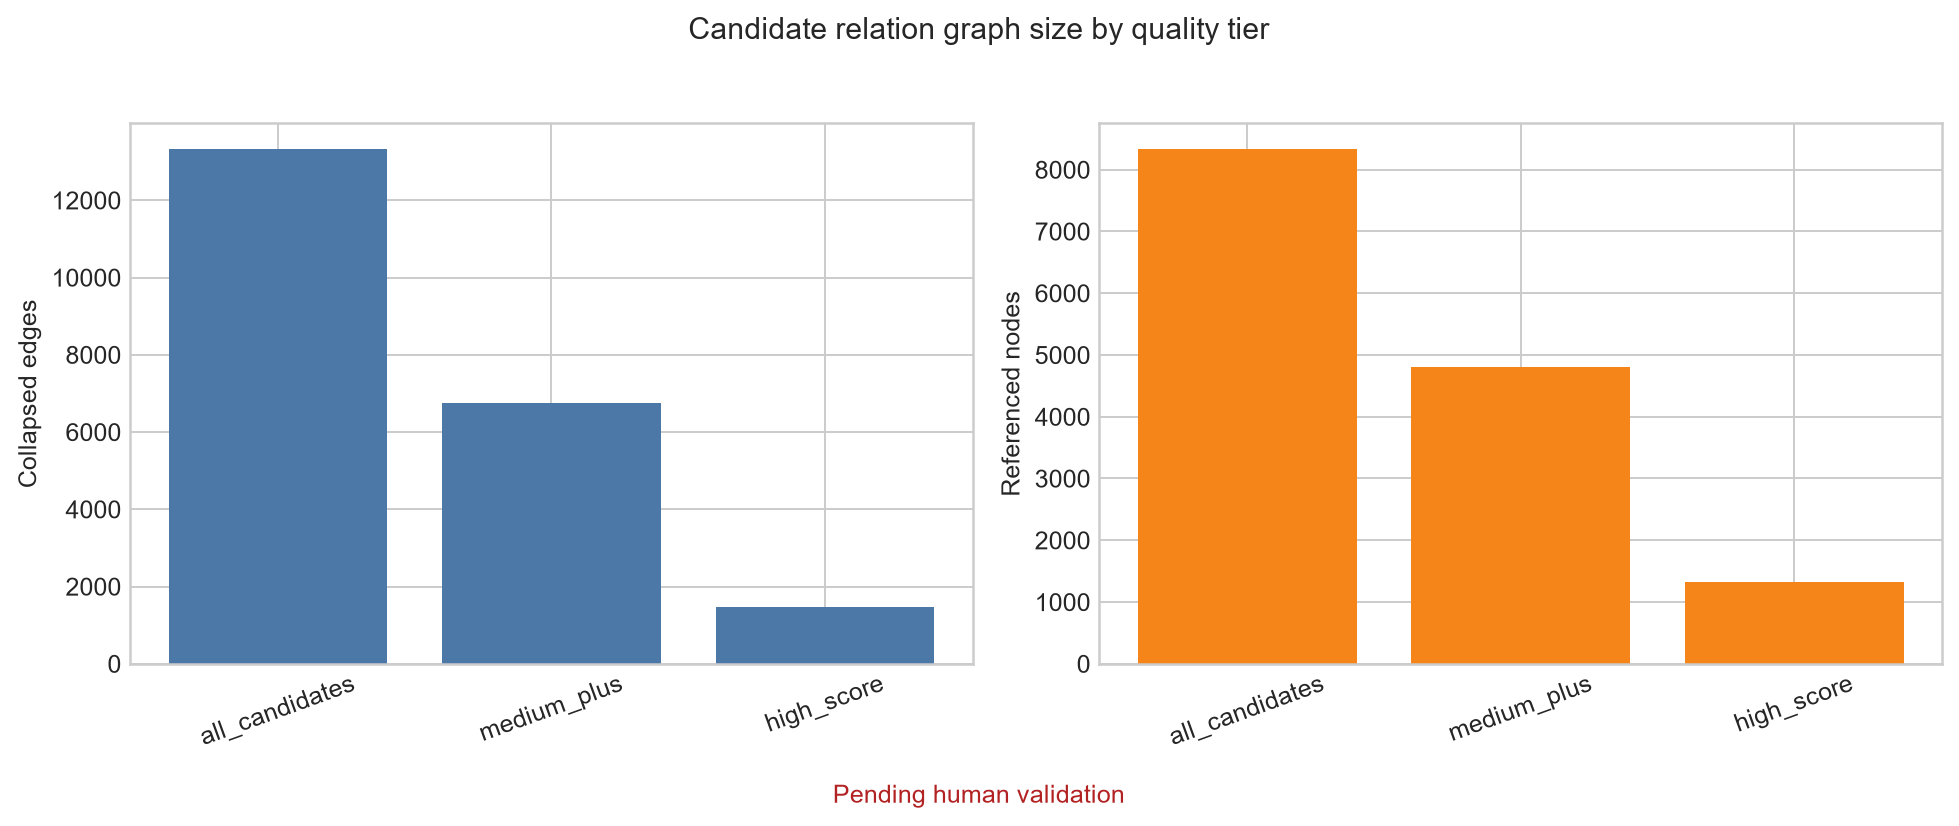

In [18]:
stability_view = relation_stability[
    relation_stability["variant_a"] != relation_stability["variant_b"]
].copy()
display(stability_view)
display(Image(filename=str(SENSITIVITY_ARTIFACT_DIR / "pagerank_top20_stability.png")))
display(Image(filename=str(SENSITIVITY_ARTIFACT_DIR / "relation_variant_sizes.png")))

all_vs_high = relation_stability[
    (relation_stability["variant_a"] == "all_candidates")
    & (relation_stability["variant_b"] == "high_score")
].iloc[0]
assert all_vs_high["top20_jaccard"] < 0.5
assert all_vs_high["pagerank_spearman"] < 0.5

전체 candidate와 high-score graph의 top-20 PageRank Jaccard는 약 0.379, 전체 순위 Spearman은
약 0.189다. 중심성 결과가 threshold에 매우 민감하므로 현재 PageRank 순위를 산업 영향력이나
최종 프로젝트 insight로 해석하지 않는다.

## 19. Co-occurrence threshold와 community 민감도

,assertion_count,node_count,component_count,largest_component_nodes,largest_component_share,density,minimum_document_count,edge_count,validation_status,community_count,largest_community_nodes
0,186710,48304,1930,43073,0.891707,0.000160,1,186710,descriptive_cooccurrence_not_semantic_relation,2543,7878
1,51522,8922,81,8690,0.973997,0.001295,2,51522,descriptive_cooccurrence_not_semantic_relation,114,2413
2,19521,2377,5,2368,0.996214,0.006913,5,19521,descriptive_cooccurrence_not_semantic_relation,13,748


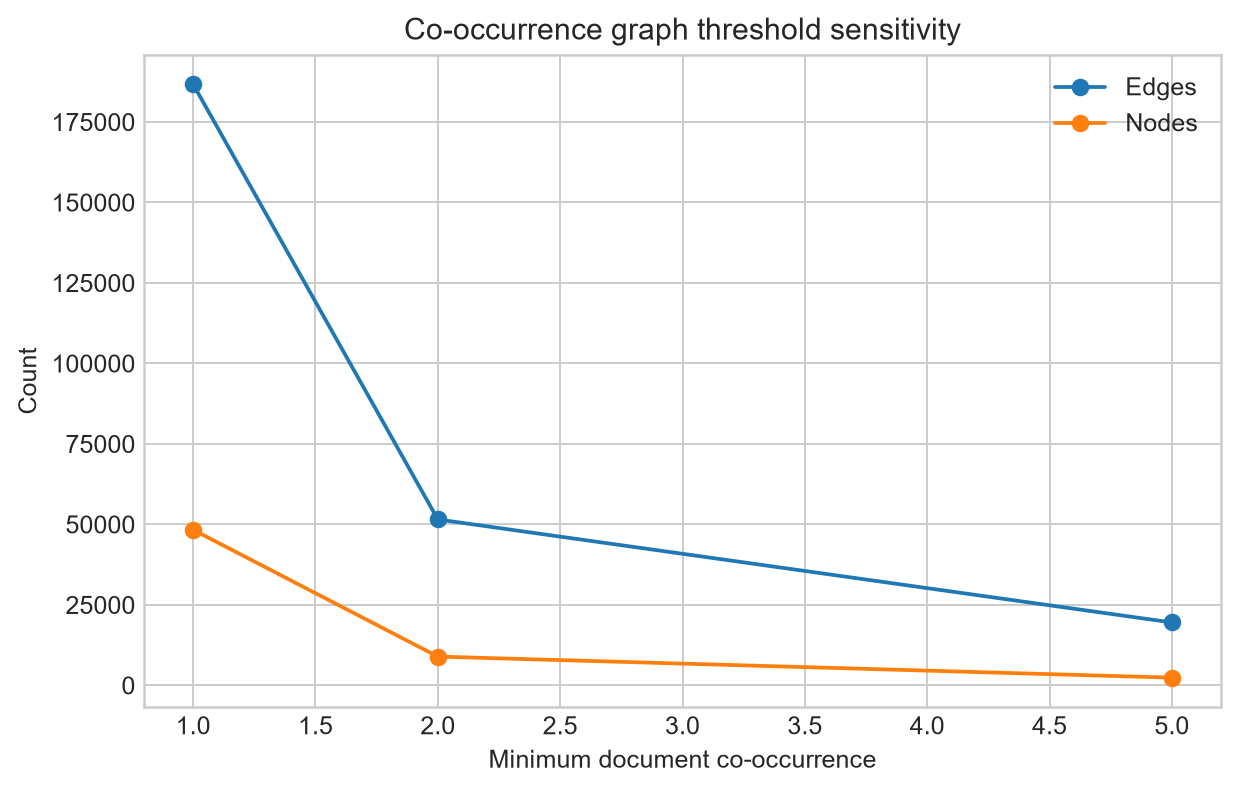

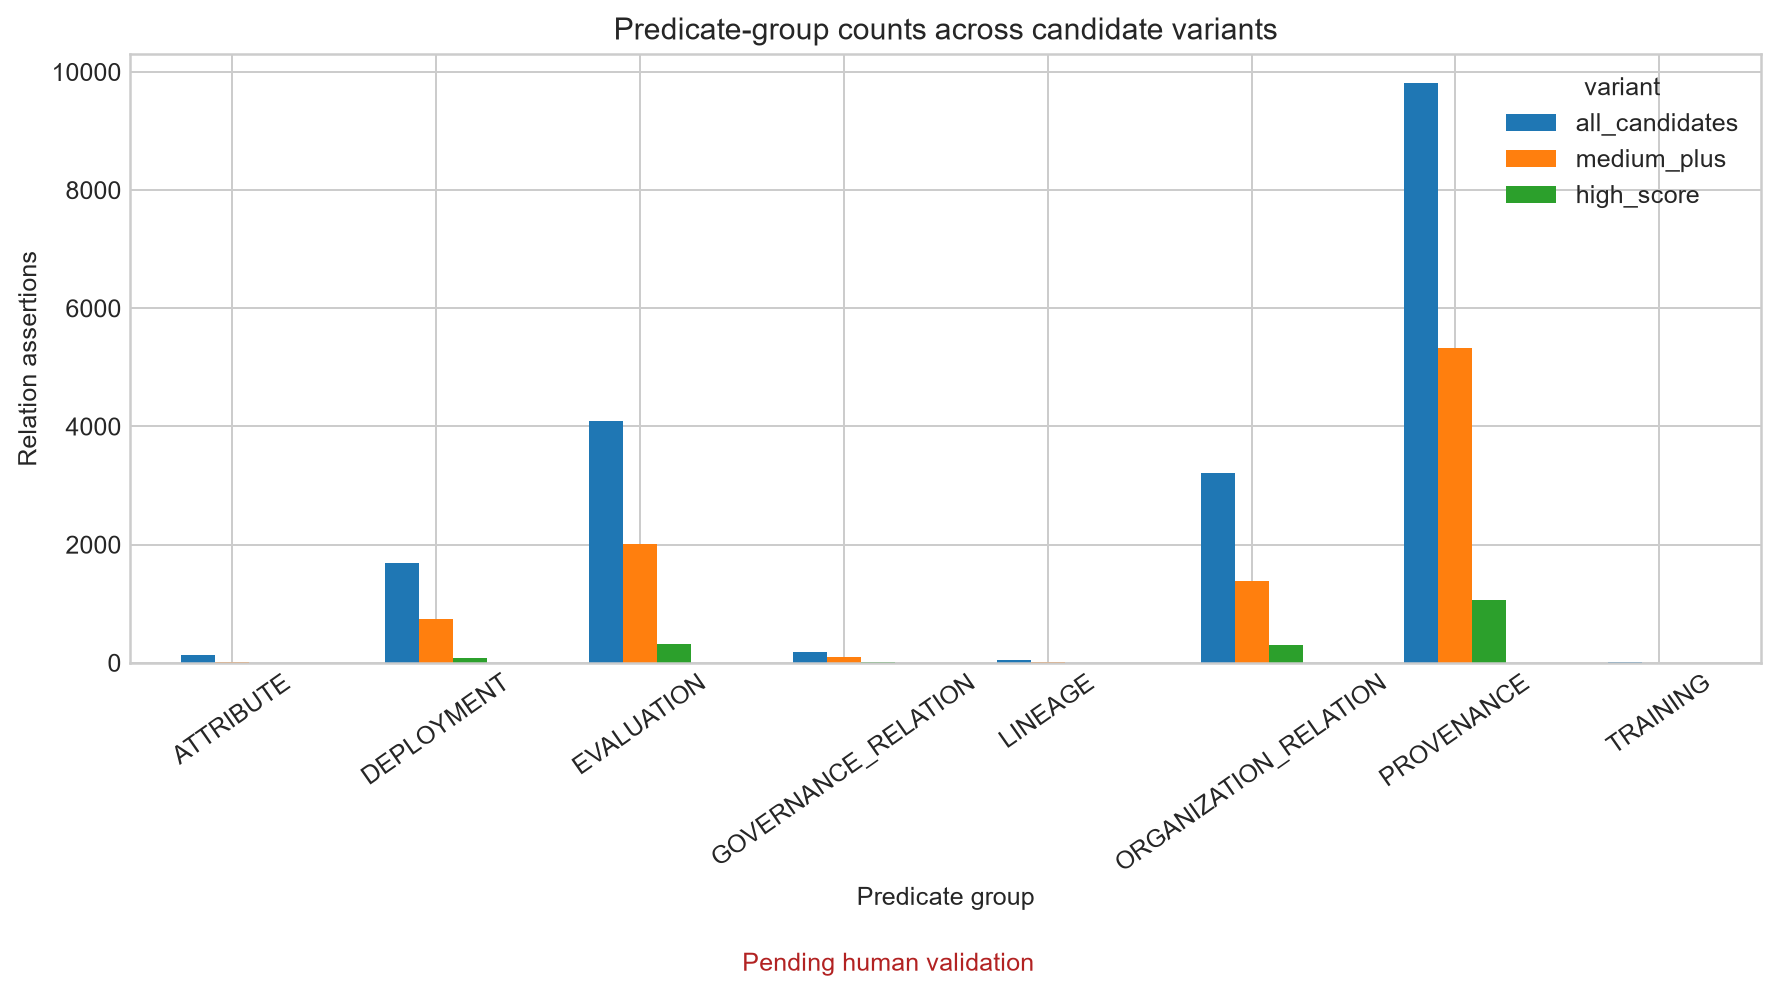

In [19]:
cooccurrence_sensitivity = pd.read_csv(
    SENSITIVITY_ARTIFACT_DIR / "cooccurrence_threshold_summary.csv"
)
display(cooccurrence_sensitivity)
display(
    Image(
        filename=str(
            SENSITIVITY_ARTIFACT_DIR / "cooccurrence_threshold_sensitivity.png"
        )
    )
)
display(Image(filename=str(SENSITIVITY_ARTIFACT_DIR / "relation_group_sensitivity.png")))

assert set(cooccurrence_sensitivity["minimum_document_count"]) == {1, 2, 5}
assert set(cooccurrence_sensitivity["validation_status"]) == {
    "descriptive_cooccurrence_not_semantic_relation"
}

공동출현을 최소 1개 문서에서 2개 문서로 올리면 node는 48,304개에서 8,922개로 줄고,
community는 2,543개에서 114개로 줄어든다. 5개 문서 기준에서는 2,377개 node와 13개 community만
남는다. coverage와 noise의 균형을 위해 문서 2개를 탐색용 기본값으로 사용하고 1·5를 sensitivity
view로 함께 보존한다. 공동출현은 의미 관계나 인과관계를 뜻하지 않는다.

## 20. 검수 전 임시 분석 정책

- typed graph의 임시 기본 view는 `medium_plus`로 둔다.
- `all_candidates`와 `high_score`를 함께 계산해 metric 안정성을 확인한다.
- 모든 figure와 table에 candidate 상태를 유지한다.
- co-occurrence 기본 view는 최소 2개 문서 공동출현으로 둔다.
- 최종 centrality, community 해석과 Stage 3 relation retrieval은 사람 검수 뒤 다시 계산한다.

현재 결과에서 “중심성이 높은 조직” 같은 사실 결론을 선택하지 않는다. 지금 확정할 수 있는 결론은
**graph metric이 relation score와 co-occurrence threshold에 민감하다**는 품질 평가뿐이다.

## 21. 검수 결과가 오기 전 남은 작업

1. 팀원이 FALSE·AMBIGUOUS 51개를 우선 재검수하고 TRUE도 교차 검수한다.
2. `evidence_supports_relation`과 `triple_plausible`을 구분해 기록한다.
3. 충분한 사람 검수 없이 predicate 전체를 허용하거나 제외하지 않는다.
4. generic entity와 저빈도 noise 처리 기준을 확정한다.
5. candidate graph와 human-validated graph를 별도 출력한다.

검수 파일을 pipeline에 연결하는 코드는 다음 단계에서 준비할 수 있다. 검수 결과가 오면 동일한
variant 분석을 human-validated graph에 다시 실행해 최종 표와 그림을 교체한다.

# WP3 3단계 — 보정 관계로 최종 지식그래프 구축 (Stage 1 완결)

2단계까지의 결론은 **raw candidate graph는 그대로 사실 그래프로 쓸 수 없다**는 것이었다. 이후
`notebooks/stage1_wp3_relation_correction.ipynb`에서 오류 원인별 규칙으로 relation을 보정했다.

- 이름 변형·별칭 병합, 잘못된 node type 수정, 일반명사 node 표시
- `Llama Nemotron`처럼 다른 제품명 안의 family 이름 연결 해제
- WP1 lexicon 개발사와 충돌하는 `developed by` 제외, 자기 회사 제품과의 `competes with` 제외
- 같은 문장 반복을 제거한 뒤 서로 다른 근거 문장이 2개 이상인 relation만 Tier B로 분류

3단계는 이 보정 결과(Tier A + B)로 과제 요구사항의 Knowledge Graph Construction을 완성한다.

1. compact topic-specific schema 확정
2. assertion·collapsed typed·co-occurrence graph 생성
3. centrality, clustering, community, 시간 분석
4. 목적별 시각화
5. 근거 문장이 연결된 insight 후보
6. Stage 3에서 다시 쓸 graph·schema·data dictionary 저장과 재로딩 검증

3단계는 디스크의 파일만 읽으므로 1·2단계를 다시 실행하지 않고 이 셀부터 실행할 수 있다.

## 22. 3단계 실행 환경

입력은 세 곳에서 읽는다.

- `outputs/stage1_wp2_open_models_official_20261007/`: 공식 WP2 handover (수정하지 않음)
- `outputs/stage1_wp3_relation_correction_20261008/`: relation correction notebook 산출물
- `artifacts/stage1_wp3/evaluation/relation_correction/`: 사람 검수용 Tier B 표본

대용량 결과는 Git-ignored `outputs/stage1_wp3_knowledge_graph_final/`에, 제출·공유용 작은 파일은
`artifacts/stage1_wp3/final/`에 저장한다.

In [20]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from stage3_graph_rag import GraphEvidenceRetriever
from wp3_knowledge_graph.pipeline import (
    build_relation_type_summary,
    calculate_node_metrics,
    calculate_relation_type_metrics,
    collapse_relations,
    detect_cooccurrence_communities,
    graph_summary,
)

WP2_INPUT_DIR = ROOT / "outputs" / "stage1_wp2_open_models_official_20261007"
CORRECTION_DIR = ROOT / "outputs" / "stage1_wp3_relation_correction_20261008"
CORRECTED_REVIEW_PATH = (
    ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"
    / "relation_review_corrected_seed2026.csv"
)
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"
WP1_CORE_PATH = ROOT / "dataset" / "processed" / "open_models_core.parquet"  # 선택: 기사 제목·URL
FINAL_OUTPUT_DIR = ROOT / "outputs" / "stage1_wp3_knowledge_graph_final"
FINAL_ARTIFACT_DIR = ROOT / "artifacts" / "stage1_wp3" / "final"
FIGURE_DIR = FINAL_ARTIFACT_DIR / "figures"
for directory in [FINAL_OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_COOCCURRENCE_DOCUMENTS = 2   # 19절 민감도 분석에서 정한 탐색용 기본값
DRAW_COOCCURRENCE_DOCUMENTS = 5  # community 그림에서만 쓰는 더 높은 기준
SEED = 42
PERIODS = {"P1 (2024-09~2025-08)": ("2024-09-01", "2025-08-31"),
           "P2 (2025-09~2026-08)": ("2025-09-01", "2026-08-31")}

for required_path in [WP2_INPUT_DIR, CORRECTION_DIR, CORRECTED_REVIEW_PATH, COMPACT_SCHEMA_PATH]:
    assert required_path.exists(), f"필수 입력이 없습니다: {required_path}"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    # The WP3 pipeline module uses the non-interactive Agg backend, so saved PNGs are displayed instead.
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def pretty(label):
    return str(label).replace("_", " ")

## 23. 보정 relation 입력과 단계별 감소

보정 notebook의 결과를 읽고, WP2 원본에서 최종 graph 후보까지 relation이 어떻게 줄었는지 확인한다.
Tier A는 WP1 lexicon의 model family → developer, Tier B는 모든 보정 검사를 통과하고 서로 다른 근거
문장이 2개 이상인 GLiREL relation이다. 같은 triple이 Tier A와 B에 모두 있으면 하나로 합치고
`sources`에 두 출처를 함께 기록했다.

In [21]:
nodes_corrected = pd.read_csv(
    CORRECTION_DIR / "nodes_corrected.csv", keep_default_na=False, na_values=[""]
)
edges_corrected = pd.read_csv(CORRECTION_DIR / "edges_relations_corrected.csv")
graph_candidates = pd.read_csv(CORRECTION_DIR / "edges_graph_candidates.csv")
evidence_corrected = pd.read_csv(CORRECTION_DIR / "relations_evidence_corrected.csv")
wp2_edges = pd.read_csv(WP2_INPUT_DIR / "edges_relations.csv")
wp2_nodes = pd.read_csv(WP2_INPUT_DIR / "nodes.csv", keep_default_na=False, na_values=[""])
wp2_cooccurrence = pd.read_csv(WP2_INPUT_DIR / "edges_cooccurrence.csv")
nodes_quarterly = pd.read_csv(WP2_INPUT_DIR / "nodes_quarterly.csv")
sentences = pd.read_csv(WP2_INPUT_DIR / "sentences.csv")
wp2_schema = json.loads((WP2_INPUT_DIR / "schema.json").read_text(encoding="utf-8"))
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))

glirel_raw = wp2_edges[wp2_edges["source"] == "glirel"]
relation_funnel = pd.DataFrame(
    [
        ("WP2 GLiREL 원본 triple", len(glirel_raw)),
        ("WP2 권장 필터: type_valid & 문장 2개 이상", int((glirel_raw["type_valid"] & (glirel_raw["n_sentences"] >= 2)).sum())),
        ("보정 후 Tier B: 모든 검사 통과 & 서로 다른 문장 2개 이상", int((edges_corrected["tier"] == "B").sum())),
        ("Tier A: WP1 lexicon model family → developer", int((edges_corrected["tier"] == "A").sum())),
        ("최종 graph 후보: Tier A+B, 동일 triple 병합", len(graph_candidates)),
    ],
    columns=["단계", "triple 수"],
)
display(relation_funnel)

exclusion_reasons = (
    edges_corrected["exclusion_reason"].dropna().str.split(";").explode()
    .value_counts().rename_axis("제외 사유").reset_index(name="triple 수")
)
display(exclusion_reasons)
display(graph_candidates["sources"].value_counts().rename_axis("출처").reset_index(name="triple 수"))

,단계,triple 수
0,WP2 GLiREL 원본 triple,22957
1,WP2 권장 필터: type_valid & 문장 2개 이상,1629
2,보정 후 Tier B: 모든 검사 통과 & 서로 다른 문장 2개 이상,1049
3,Tier A: WP1 lexicon model family → developer,33
4,"최종 graph 후보: Tier A+B, 동일 triple 병합",1067


,제외 사유,triple 수
0,type_invalid,9155
1,generic_node,6876
2,conflicts_lexicon_developer,438
3,reverse_duplicate,223
4,own_product_or_parent,92


,출처,triple 수
0,glirel,1034
1,wp1_lexicon,18
2,glirel | wp1_lexicon,15


WP2 권장 필터의 1,629개 대신 1,067개 triple을 사용한다. 줄어든 이유는 점수 threshold가 아니라 구체적인
오류 원인이다. 가장 큰 제외 사유는 schema type 위반과 `model`, `company`, `AI` 같은 일반명사 node다.
Tier C(근거 문장 1개)와 X(제외)도 삭제하지 않고 보정 산출물에 사유와 함께 남아 있다.

## 24. 사람 검수 결과 반영 규칙

Tier B 표본 90개(`relation_review_corrected_seed2026.csv`)는 팀원 3명이 30개씩 검수한다. 이 셀은
검수 파일을 읽어 다음 규칙을 적용한다. 검수가 아직 없으면 graph는 `candidate` 상태로 유지된다.

- `FALSE`로 판정된 triple은 graph에서 제외한다.
- 검수 행이 90개 이상이고 precision이 0.80 이상이면 graph 상태를 `human_validated_sample`로 바꾼다.
- `AMBIGUOUS`는 precision 계산에서 제외하고 개수만 보고한다.

AI가 작성한 판정 초안은 이 계산에 사용하지 않는다.

In [22]:
TRIPLE = ["head_id", "relation", "tail_id"]
review = pd.read_csv(CORRECTED_REVIEW_PATH)
review_labels = review["review_correct"].astype("string").str.strip().str.upper()
review_counts = review_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
decided = int(review_counts["TRUE"] + review_counts["FALSE"])
review_precision = review_counts["TRUE"] / decided if decided else np.nan
GRAPH_STATUS = (
    "human_validated_sample"
    if review_labels.notna().sum() >= 90 and review_precision >= 0.80
    else "candidate_pending_human_review"
)

review_keys = review.assign(review_label=review_labels).rename(columns={"predicate": "relation"})[
    TRIPLE + ["review_label"]
]
final_edges = graph_candidates.merge(review_keys, on=TRIPLE, how="left", validate="one_to_one")
label = final_edges["review_label"].astype(object).fillna("")
final_edges["review_status"] = np.select(
    [label.eq("TRUE"), label.eq("FALSE"), label.eq("AMBIGUOUS"), final_edges["tier"].eq("A")],
    ["reviewed_true", "reviewed_false", "reviewed_ambiguous", "curated_lexicon"],
    default="unreviewed",
)
final_edges = final_edges[final_edges["review_status"] != "reviewed_false"].reset_index(drop=True)

display(pd.DataFrame(
    [
        ("검수 표본 행 수", len(review)),
        ("검수 완료 행 수", int(review_labels.notna().sum())),
        ("TRUE / FALSE / AMBIGUOUS", " / ".join(str(int(v)) for v in review_counts)),
        ("Tier B 표본 precision", "검수 전" if np.isnan(review_precision) else f"{review_precision:.3f}"),
        ("FALSE로 제외한 triple", len(graph_candidates) - len(final_edges)),
        ("최종 graph triple", len(final_edges)),
        ("graph 상태", GRAPH_STATUS),
    ],
    columns=["항목", "값"],
))

,항목,값
0,검수 표본 행 수,90
1,검수 완료 행 수,0
2,TRUE / FALSE / AMBIGUOUS,0 / 0 / 0
3,Tier B 표본 precision,검수 전
4,FALSE로 제외한 triple,0
5,최종 graph triple,1067
6,graph 상태,candidate_pending_human_review


## 25. Compact topic-specific schema 확정

과제는 graph를 만들기 전에 compact schema를 정의하도록 요구한다. WP2의 20개 entity type과 36개
relation type은 추출 recall을 위한 넓은 schema이므로, 분석에는 2단계에서 정한 상위 그룹을 쓴다.

- **node**: 9개 compact entity type. 원래 type은 `entity_type`에 그대로 남긴다.
- **edge**: 실제 graph에 남은 raw relation type과 이를 묶는 8개 predicate group
- `competes with`는 대칭 관계라 방향이 없다. 나머지는 head → tail 방향이 의미를 가진다
  (예: `Llama → developed by → Meta`).
- 날짜는 **기사 발행일**이다. 모델 출시일이나 사건 발생일이 아니다.

In [23]:
ENTITY_GROUP = compact_schema["entity_type_mapping"]
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
SYMMETRIC_PREDICATES = {"competes with"}
COMPACT_TYPE_DEFINITIONS = {
    "MODEL": "AI model or open model family (WP1 lexicon families and other models)",
    "ORGANIZATION": "company, lab, institution or agency",
    "PERSON": "named person",
    "INFRASTRUCTURE": "hardware, platform or product used to build, host or run models",
    "TECHNICAL_COMPONENT": "technology, tool or model architecture",
    "MODEL_ATTRIBUTE": "capability, openness concept or model specification",
    "EVALUATION_RESOURCE": "benchmark or dataset",
    "GOVERNANCE": "license, standard or law",
    "LOCATION_OR_GROUP": "country, city, region or nationality group",
}

nodes_kg = nodes_corrected.rename(
    columns={"entity": "canonical_name", "mentions": "mention_count", "n_docs": "document_count"}
)
nodes_kg["mention_count"] = nodes_kg["mention_count"].fillna(0).astype(int)
nodes_kg["document_count"] = nodes_kg["document_count"].fillna(0).astype(int)
nodes_kg["entity_type_compact"] = nodes_kg["entity_type"].map(ENTITY_GROUP)
nodes_kg["is_open_model_family"] = nodes_kg["canonical_id"].notna() & nodes_kg["entity_type"].eq("FOUNDATION_MODEL")
final_edges["predicate_group"] = final_edges["relation"].map(PREDICATE_GROUP)
final_edges["directed"] = ~final_edges["relation"].isin(SYMMETRIC_PREDICATES)
assert final_edges["predicate_group"].notna().all()

wp2_relation_types = wp2_schema["edges"]["relation"]["types"]
endpoint_types = final_edges.assign(
    head_compact=final_edges["head_type"].map(ENTITY_GROUP),
    tail_compact=final_edges["tail_type"].map(ENTITY_GROUP),
)
relation_schema_table = (
    endpoint_types.groupby(["predicate_group", "relation"])
    .agg(triples=("head_id", "size"),
         head_types=("head_compact", lambda x: ", ".join(sorted(set(x)))),
         tail_types=("tail_compact", lambda x: ", ".join(sorted(set(x)))),
         directed=("directed", "first"))
    .reset_index()
    .sort_values(["predicate_group", "triples"], ascending=[True, False])
)
display(relation_schema_table)

graph_schema = {
    "schema_version": "stage1-wp3-open-models-kg-v1.0",
    "status": GRAPH_STATUS,
    "track": "Open Models",
    "node_key": "entity_id",
    "node_attributes": ["canonical_name", "entity_type", "entity_type_compact", "mention_count",
                        "document_count", "first_seen", "last_seen", "is_open_model_family", "aliases"],
    "entity_types": {
        compact: {"definition": COMPACT_TYPE_DEFINITIONS[compact],
                  "wp2_entity_types": sorted(t for t, c in ENTITY_GROUP.items() if c == compact)}
        for compact in COMPACT_TYPE_DEFINITIONS
    },
    "relation_types": {
        row.relation: {
            "group": row.predicate_group,
            "directed": bool(row.directed),
            "observed_head_types": row.head_types.split(", "),
            "observed_tail_types": row.tail_types.split(", "),
            "definition": wp2_relation_types[row.relation]["definition"],
        }
        for row in relation_schema_table.itertuples(index=False)
    },
    "edge_quality_tiers": {
        "A": "curated WP1 lexicon model family -> developer (no article sentence)",
        "B": "GLiREL relation passing all WP3 correction checks with >= 2 distinct evidence sentences",
    },
    "review_status_values": ["curated_lexicon", "unreviewed", "reviewed_true", "reviewed_ambiguous"],
    "graph_views": {
        "assertion": "directed multigraph, one edge per evidence sentence (edge key = relation_id)",
        "typed": "directed multigraph, one edge per unique (head, relation, tail); competes with is symmetric",
        "cooccurrence": f"undirected weighted graph of same-sentence co-mentions in >= {MIN_COOCCURRENCE_DOCUMENTS} documents",
    },
    "edge_weight": "document_count = number of distinct articles supporting the edge",
    "date_semantics": "published_at / first_seen / last_seen are article publication dates, not release or event dates",
    "provenance_chain": ["entity_id", "relation_id", "text_unit_id (doc_id:sentence_id)", "document_id", "published_at"],
}
compact_counts = (
    nodes_kg[nodes_kg["entity_id"].isin(set(final_edges["head_id"]) | set(final_edges["tail_id"]))]
    ["entity_type_compact"].value_counts().rename_axis("compact entity type").reset_index(name="typed graph node 수")
)
display(compact_counts)

,predicate_group,relation,triples,head_types,tail_types,directed
0,DEPLOYMENT,available on,30,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
3,DEPLOYMENT,supported by,18,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, ORGANIZATION, TECHNICAL_COMPONENT",True
2,DEPLOYMENT,runs on,9,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
4,DEPLOYMENT,used by,4,"INFRASTRUCTURE, MODEL",ORGANIZATION,True
1,DEPLOYMENT,integrated into,2,MODEL,INFRASTRUCTURE,True
5,EVALUATION,competes with,245,"INFRASTRUCTURE, MODEL, ORGANIZATION","INFRASTRUCTURE, MODEL, ORGANIZATION, TECHNICAL...",False
6,EVALUATION,outperforms,43,"INFRASTRUCTURE, MODEL","INFRASTRUCTURE, MODEL",True
8,GOVERNANCE_RELATION,licensed under,9,"MODEL, TECHNICAL_COMPONENT",GOVERNANCE,True
7,GOVERNANCE_RELATION,complies with,1,ORGANIZATION,GOVERNANCE,True
9,GOVERNANCE_RELATION,regulated by,1,ORGANIZATION,GOVERNANCE,True


,compact entity type,typed graph node 수
0,ORGANIZATION,210
1,INFRASTRUCTURE,189
2,MODEL,170
3,PERSON,118
4,TECHNICAL_COMPONENT,48
5,LOCATION_OR_GROUP,21
6,GOVERNANCE,10
7,EVALUATION_RESOURCE,9


## 26. 세 가지 graph view 생성

과제의 "nodes represent entities and edges represent co-mentions or extracted relations"를 세 view로
나누어 구현한다. typed relation과 co-occurrence는 의미가 다르므로 같은 graph에 섞지 않는다.

| view | NetworkX 구조 | edge 단위 | 용도 |
|---|---|---|---|
| assertion | `MultiDiGraph` | 근거 문장 1개 | provenance, Stage 3 근거 passage 회수 |
| typed | `MultiDiGraph` | unique triple 1개 | centrality, relation별 분석, 발표용 graph |
| co-occurrence | `Graph` | entity 쌍 1개 | community, clustering, 담론 구조 |

Co-occurrence는 WP2의 `edges_cooccurrence.csv`를 보정 node ID로 다시 매핑하고, 일반명사 node와
문서 2개 미만의 쌍을 제외한다.

In [24]:
def text_unit(doc_ids, sentence_ids):
    return [f"{d}:{int(s)}" for d, s in zip(doc_ids, sentence_ids)]

# 1) Assertion table: GLiREL evidence of the graph triples + curated lexicon rows
ok_evidence = evidence_corrected[evidence_corrected["evidence_status"] == "ok"]
glirel_keys = final_edges.loc[final_edges["sources"].str.contains("glirel"), TRIPLE]
glirel_assertions = ok_evidence.merge(glirel_keys, on=TRIPLE, how="inner")
glirel_assertions = pd.DataFrame({
    "subject_id": glirel_assertions["head_id"],
    "predicate": glirel_assertions["relation"],
    "object_id": glirel_assertions["tail_id"],
    "document_id": glirel_assertions["doc_id"],
    "text_unit_id": text_unit(glirel_assertions["doc_id"], glirel_assertions["sentence_id"]),
    "evidence_text": glirel_assertions["sentence_text"],
    "published_at": glirel_assertions["date"],
    "extraction_method": "glirel",
    "rule_score": glirel_assertions["score"],
    "assertion_status": "asserted",
})
lexicon_rows = final_edges[final_edges["sources"].str.contains("wp1_lexicon")]
lexicon_assertions = pd.DataFrame({
    "subject_id": lexicon_rows["head_id"], "predicate": lexicon_rows["relation"],
    "object_id": lexicon_rows["tail_id"], "document_id": pd.NA, "text_unit_id": pd.NA,
    "evidence_text": pd.NA, "published_at": pd.NA, "extraction_method": "wp1_lexicon",
    "rule_score": np.nan, "assertion_status": "asserted",
})
assertions = pd.concat([glirel_assertions, lexicon_assertions], ignore_index=True)
assertions.insert(0, "relation_id", [
    "rel_" + hashlib.sha1("|".join(map(str, key)).encode()).hexdigest()[:16]
    for key in assertions[["subject_id", "predicate", "object_id", "text_unit_id", "extraction_method"]]
    .itertuples(index=False, name=None)
])
assertions = assertions.drop_duplicates("relation_id").reset_index(drop=True)
assert set(map(tuple, glirel_keys.values)) <= set(
    zip(glirel_assertions["subject_id"], glirel_assertions["predicate"], glirel_assertions["object_id"])
), "every GLiREL graph triple needs at least one evidence sentence"

# 2) Collapsed typed edges: evidence aggregates from the WP3 pipeline + correction attributes
collapsed = collapse_relations(assertions, documents=None)
edge_attributes = final_edges.rename(columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"})[
    ["subject_id", "predicate", "object_id", "tier", "sources", "review_status", "predicate_group",
     "directed", "n_distinct_sentences", "mean_score"]
]
collapsed = collapsed.merge(edge_attributes, on=["subject_id", "predicate", "object_id"], how="left", validate="one_to_one")
collapsed["weight"] = collapsed["document_count"].clip(lower=1)
assert len(collapsed) == len(final_edges)

# 3) Co-occurrence edges remapped to the corrected node ids
id_map = (nodes_corrected.assign(original_id=nodes_corrected["merged_ids"].str.split(" | ", regex=False))
          .explode("original_id").set_index("original_id")["entity_id"])
generic_ids = set(nodes_corrected.loc[nodes_corrected["is_generic"], "entity_id"])
co = wp2_cooccurrence.assign(
    a=wp2_cooccurrence["entity1_id"].map(id_map), b=wp2_cooccurrence["entity2_id"].map(id_map)
)
co = co[(co["a"] != co["b"]) & ~co["a"].isin(generic_ids) & ~co["b"].isin(generic_ids)].copy()
ordered = np.sort(co[["a", "b"]].to_numpy(dtype=str), axis=1)
co["source_id"], co["target_id"] = ordered[:, 0], ordered[:, 1]
cooccurrence_all = (
    co.groupby(["source_id", "target_id"])
    .agg(sentence_count=("sentence_cooccurrence", "sum"), document_count=("document_cooccurrence", "sum"),
         npmi=("npmi", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
         merged_pairs=("entity1_id", "size"))
    .reset_index()
)
cooccurrence_edges = cooccurrence_all[cooccurrence_all["document_count"] >= MIN_COOCCURRENCE_DOCUMENTS].reset_index(drop=True)

# 4) NetworkX graphs
node_index = nodes_kg.set_index("entity_id")
def node_attributes(entity_id):
    row = node_index.loc[entity_id]
    return {"label": row["canonical_name"], "entity_type": row["entity_type"],
            "entity_type_compact": row["entity_type_compact"], "mention_count": int(row["mention_count"]),
            "document_count": int(row["document_count"]), "first_seen": row["first_seen"] or "",
            "last_seen": row["last_seen"] or "", "is_open_model_family": bool(row["is_open_model_family"])}

def scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if pd.notna(value) else -1.0
    return "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)

assertion_graph = nx.MultiDiGraph(graph_view="assertion", schema_version=graph_schema["schema_version"])
typed_graph = nx.MultiDiGraph(graph_view="typed", schema_version=graph_schema["schema_version"])
cooccurrence_graph = nx.Graph(graph_view="cooccurrence", schema_version=graph_schema["schema_version"])
for graph, endpoints in [
    (assertion_graph, set(assertions["subject_id"]) | set(assertions["object_id"])),
    (typed_graph, set(collapsed["subject_id"]) | set(collapsed["object_id"])),
    (cooccurrence_graph, set(cooccurrence_edges["source_id"]) | set(cooccurrence_edges["target_id"])),
]:
    graph.add_nodes_from((entity_id, node_attributes(entity_id)) for entity_id in sorted(endpoints))

for row in assertions.itertuples(index=False):
    assertion_graph.add_edge(row.subject_id, row.object_id, key=row.relation_id, predicate=row.predicate,
                             document_id=scalar(row.document_id), text_unit_id=scalar(row.text_unit_id),
                             published_at=scalar(row.published_at), extraction_method=row.extraction_method,
                             rule_score=scalar(row.rule_score))
typed_columns = ["predicate", "predicate_group", "directed", "tier", "sources", "review_status", "evidence_count",
                 "document_count", "n_distinct_sentences", "weight", "first_seen", "last_seen", "mean_rule_score",
                 "text_unit_ids"]
for row in collapsed.itertuples(index=False):
    typed_graph.add_edge(row.subject_id, row.object_id, key=row.predicate,
                         **{column: scalar(getattr(row, column)) for column in typed_columns})
for row in cooccurrence_edges.itertuples(index=False):
    cooccurrence_graph.add_edge(row.source_id, row.target_id, sentence_count=int(row.sentence_count),
                                document_count=int(row.document_count), npmi=float(row.npmi),
                                first_seen=scalar(row.first_seen), last_seen=scalar(row.last_seen))

display(pd.DataFrame(
    [
        ("assertion", assertion_graph.number_of_nodes(), assertion_graph.number_of_edges(), "근거 문장 + lexicon"),
        ("typed", typed_graph.number_of_nodes(), typed_graph.number_of_edges(), "unique triple"),
        ("co-occurrence", cooccurrence_graph.number_of_nodes(), cooccurrence_graph.number_of_edges(),
         f"문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상 공동출현"),
    ],
    columns=["view", "node", "edge", "edge 단위"],
))
print(f"co-occurrence: 일반명사 제외 후 {len(cooccurrence_all):,}쌍 중 문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상 "
      f"{len(cooccurrence_edges):,}쌍 | 병합으로 합쳐진 쌍 {int((cooccurrence_all['merged_pairs'] > 1).sum()):,}개")

,view,node,edge,edge 단위
0,assertion,775,5447,근거 문장 + lexicon
1,typed,775,1067,unique triple
2,co-occurrence,4858,23226,문서 2개 이상 공동출현


co-occurrence: 일반명사 제외 후 88,864쌍 중 문서 2개 이상 23,226쌍 | 병합으로 합쳐진 쌍 412개


보정으로 합쳐진 node 쌍의 co-occurrence 문서 수는 원래 쌍의 문서 수를 더한 값이라, 같은 기사가 두
번 세어질 수 있는 상한값이다. 해당 쌍의 수를 위에 함께 출력했다.

## 27. 기본 구조 통계

node·edge 수, density, component, relation type별 edge 수를 먼저 본다. density가 매우 낮고 component가
많으면 graph metric을 전체 산업 구조로 일반화하기 어렵다는 뜻이므로, 이후 해석의 범위를 정하는 기준이 된다.

,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components,largest_component_nodes
assertion,775.0,5447.0,1018.0,0.001697,90.0,0.0,NaN,NaN
typed,775.0,1067.0,1018.0,0.001697,90.0,0.0,NaN,563.0
co-occurrence,4858.0,23226.0,23226.0,0.001969,NaN,0.0,83.0,4609.0


,predicate,predicate_group,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,developed by,PROVENANCE,398,354,95,2257,1605,2024-09-12,2026-08-27
1,competes with,EVALUATION,245,77,73,1795,1562,2024-09-13,2026-08-27
2,works for,ORGANIZATION_RELATION,90,82,53,261,193,2024-09-25,2026-08-11
3,headquartered in,ORGANIZATION_RELATION,63,40,21,255,230,2024-10-23,2026-08-27
4,founded by,PROVENANCE,55,39,43,211,166,2024-09-13,2026-08-20
5,outperforms,EVALUATION,43,23,20,126,106,2024-09-25,2026-08-11
6,invested in,ORGANIZATION_RELATION,31,16,14,109,99,2024-10-23,2026-06-14
7,available on,DEPLOYMENT,30,20,10,105,94,2024-09-12,2026-08-11
8,manufactured by,PROVENANCE,23,23,8,57,51,2024-11-13,2026-08-11
9,acquired by,ORGANIZATION_RELATION,18,16,10,49,42,2024-09-18,2026-07-23


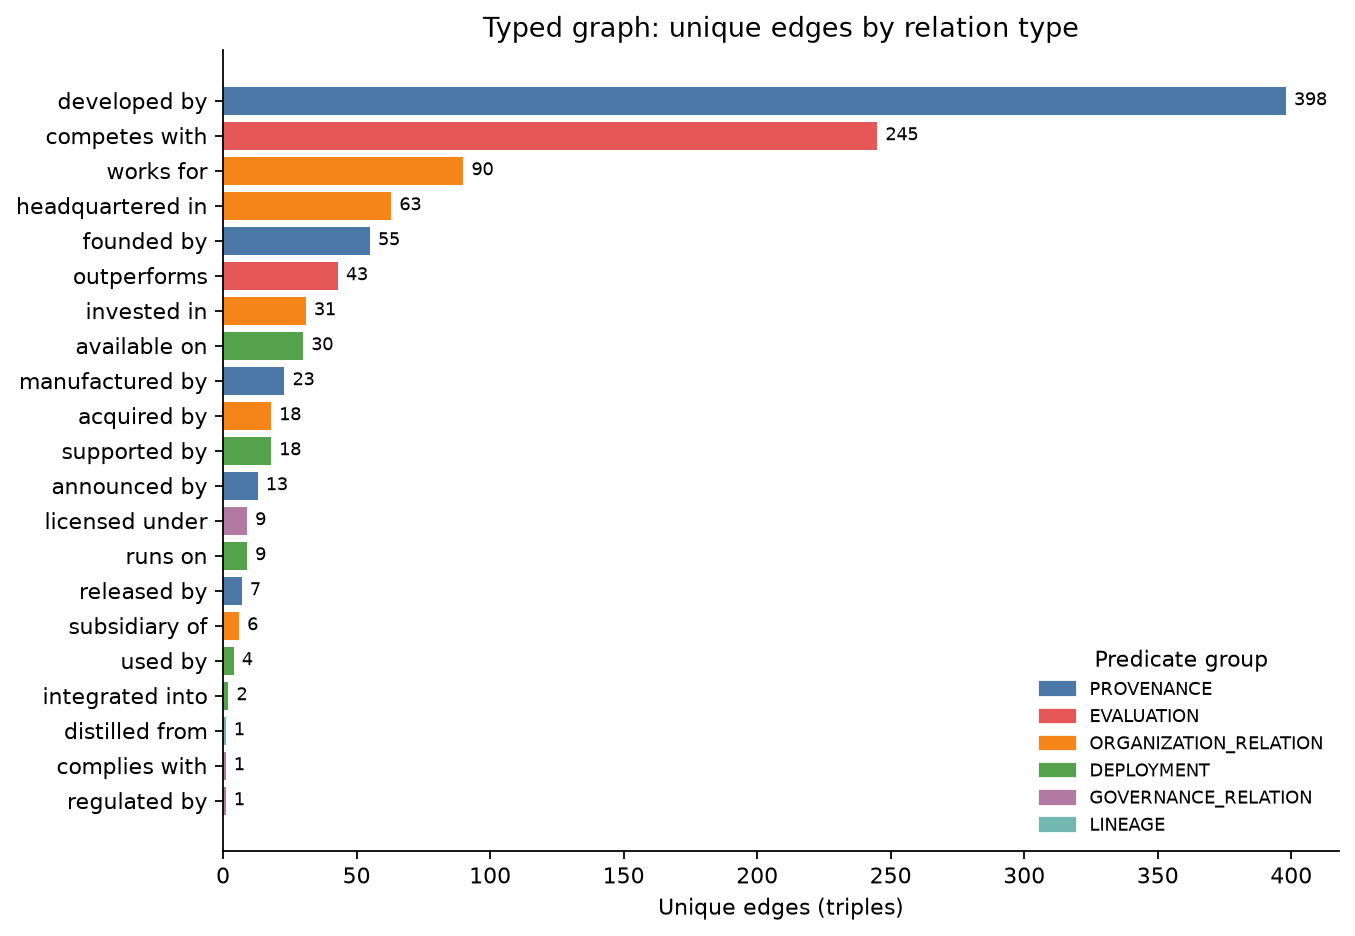

In [25]:
structure = pd.DataFrame(
    {name: graph_summary(graph) for name, graph in
     [("assertion", assertion_graph), ("typed", typed_graph), ("co-occurrence", cooccurrence_graph)]}
).T
typed_undirected = nx.Graph(typed_graph.to_undirected())
largest_component = max(nx.connected_components(typed_undirected), key=len)
structure.loc["typed", "largest_component_nodes"] = len(largest_component)
cooc_largest = max(nx.connected_components(cooccurrence_graph), key=len)
structure.loc["co-occurrence", "largest_component_nodes"] = len(cooc_largest)
display(structure)

relation_summary = build_relation_type_summary(collapsed)
relation_summary.insert(1, "predicate_group", relation_summary["predicate"].map(PREDICATE_GROUP))
display(relation_summary)

GROUP_COLORS = {
    "PROVENANCE": "#4C78A8", "EVALUATION": "#E45756", "ORGANIZATION_RELATION": "#F58518",
    "DEPLOYMENT": "#54A24B", "GOVERNANCE_RELATION": "#B279A2", "LINEAGE": "#72B7B2",
    "ATTRIBUTE": "#9D755D", "TRAINING": "#EECA3B",
}
COMPACT_COLORS = {
    "MODEL": "#4C78A8", "ORGANIZATION": "#F58518", "PERSON": "#9D755D", "INFRASTRUCTURE": "#72B7B2",
    "TECHNICAL_COMPONENT": "#54A24B", "MODEL_ATTRIBUTE": "#B279A2", "EVALUATION_RESOURCE": "#EECA3B",
    "GOVERNANCE": "#E45756", "LOCATION_OR_GROUP": "#BAB0AC",
}
plot_data = relation_summary.sort_values("unique_edges")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plot_data["predicate"], plot_data["unique_edges"],
        color=plot_data["predicate_group"].map(GROUP_COLORS))
for y, value in enumerate(plot_data["unique_edges"]):
    ax.text(value + 3, y, str(value), va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items() if g in set(plot_data["predicate_group"])],
          title="Predicate group", frameon=False, loc="lower right", fontsize=8)
ax.set(title="Typed graph: unique edges by relation type", xlabel="Unique edges (triples)", ylabel="")
save_figure(fig, "01_relation_type_counts.png")

## 28. Centrality 분석

**왜**: 어떤 entity가 관계망의 중심에 있는지 보기 위해서다. 세 가지 지표를 함께 본다.

- weighted degree: 연결된 relation의 근거 기사 수 합
- PageRank: 중요한 node와 연결될수록 커지는 점수 (edge weight = 근거 기사 수)
- betweenness: 서로 다른 영역을 잇는 다리 역할 (샘플 기반 근사)

typed graph의 PageRank와 betweenness는 방향을 무시한 projection에서 계산한다. 방향이 의미를 가지는
relation은 아래에서 relation별 in/out degree로 따로 해석한다. 예를 들어 `developed by`는 모델 → 조직
방향이므로 조직의 in-degree가 "graph에서 확인된 개발 산출물 수"가 된다.

In [26]:
typed_metrics = calculate_node_metrics(typed_graph, "typed", "weight", sample_size=1000, seed=SEED)
cooc_metrics = calculate_node_metrics(cooccurrence_graph, "cooccurrence", "document_count", sample_size=500, seed=SEED)
for metrics in (typed_metrics, cooc_metrics):
    metrics["entity_type_compact"] = metrics["entity_id"].map(node_index["entity_type_compact"])

metric_columns = ["canonical_name", "entity_type_compact", "degree", "in_degree", "out_degree",
                  "weighted_degree", "pagerank", "betweenness"]
print("Typed graph - PageRank 상위 15")
display(typed_metrics.head(15)[metric_columns].round(4))
print("Co-occurrence graph - PageRank 상위 15")
display(cooc_metrics.head(15)[[c for c in metric_columns if c in cooc_metrics]].round(4))

relation_metrics = calculate_relation_type_metrics(nodes_kg, collapsed, sample_size=300, seed=SEED)
relation_views = {
    "developed by": ("in_degree", "개발 산출물이 가장 많이 연결된 조직"),
    "competes with": ("degree", "경쟁 관계가 가장 많은 entity"),
    "works for": ("in_degree", "소속 인물이 가장 많이 연결된 조직"),
    "outperforms": ("out_degree", "다른 모델보다 낫다고 서술된 횟수가 많은 모델"),
}
for predicate, (column, description) in relation_views.items():
    view = relation_metrics[relation_metrics["predicate"] == predicate]
    print(f"[{predicate}] {description} ({column} 기준)")
    display(view.sort_values([column, "weighted_degree"], ascending=False)
                .head(8)[["canonical_name", "entity_type", column, "weighted_degree"]])

Typed graph - PageRank 상위 15


,canonical_name,entity_type_compact,degree,in_degree,out_degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,161,146,15,612.0,0.0630,0.2507
1,OpenAI,ORGANIZATION,101,85,16,880.0,0.0550,0.3048
2,Google,ORGANIZATION,113,96,17,663.0,0.0479,0.2159
3,DeepSeek,ORGANIZATION,61,35,26,586.0,0.0351,0.2547
4,Meta,ORGANIZATION,57,43,14,427.0,0.0277,0.0634
5,Anthropic,ORGANIZATION,60,40,20,382.0,0.0250,0.0668
6,Microsoft,ORGANIZATION,51,35,16,256.0,0.0188,0.0584
7,Llama,MODEL,24,10,14,202.0,0.0116,0.0011
8,Amazon,ORGANIZATION,28,14,14,132.0,0.0094,0.0259
9,Nemotron,MODEL,9,1,8,102.0,0.0089,0.0157


Co-occurrence graph - PageRank 상위 15


,canonical_name,entity_type_compact,degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,1099,11402.0,0.0319,0.3095
1,DeepSeek,ORGANIZATION,905,12343.0,0.0311,0.1785
2,OpenAI,ORGANIZATION,729,12815.0,0.0303,0.2909
3,Google,ORGANIZATION,802,10917.0,0.0279,0.2157
4,united_states,LOCATION_OR_GROUP,632,9174.0,0.0219,0.1068
5,open_source_model,MODEL_ATTRIBUTE,543,9129.0,0.0214,0.1213
6,Llama,MODEL,611,8206.0,0.0206,0.0947
7,China,LOCATION_OR_GROUP,501,7044.0,0.0166,0.0428
8,Meta,ORGANIZATION,438,6852.0,0.0157,0.0379
9,Anthropic,ORGANIZATION,419,6936.0,0.0155,0.0256


[developed by] 개발 산출물이 가장 많이 연결된 조직 (in_degree 기준)


...

,canonical_name,entity_type,degree,weighted_degree
69,Google,COMPANY,35,378.0
68,OpenAI,COMPANY,29,471.0
70,DeepSeek,COMPANY,29,332.0
71,Anthropic,COMPANY,26,261.0
73,NVIDIA,COMPANY,21,112.0
72,Meta,COMPANY,19,213.0
74,Microsoft,COMPANY,16,142.0
75,Alibaba,COMPANY,15,99.0


[works for] 소속 인물이 가장 많이 연결된 조직 (in_degree 기준)


,canonical_name,entity_type,in_degree,weighted_degree
948,NVIDIA,COMPANY,10,26.0
949,Meta,COMPANY,6,29.0
950,Microsoft,COMPANY,6,14.0
951,Google,COMPANY,6,9.0
955,OpenAI,COMPANY,3,12.0
953,Anthropic,COMPANY,3,6.0
952,IBM,COMPANY,3,5.0
954,Red Hat,COMPANY,3,3.0


[outperforms] 다른 모델보다 낫다고 서술된 횟수가 많은 모델 (out_degree 기준)


,canonical_name,entity_type,out_degree,weighted_degree
844,GPT-4o,AI_MODEL,7,22.0
842,Qwen,FOUNDATION_MODEL,5,30.0
845,Kimi,FOUNDATION_MODEL,4,16.0
847,Mistral,FOUNDATION_MODEL,3,13.0
849,GLM,FOUNDATION_MODEL,3,9.0
855,Phi,FOUNDATION_MODEL,3,7.0
843,Llama,FOUNDATION_MODEL,2,28.0
846,Claude,AI_MODEL,1,14.0


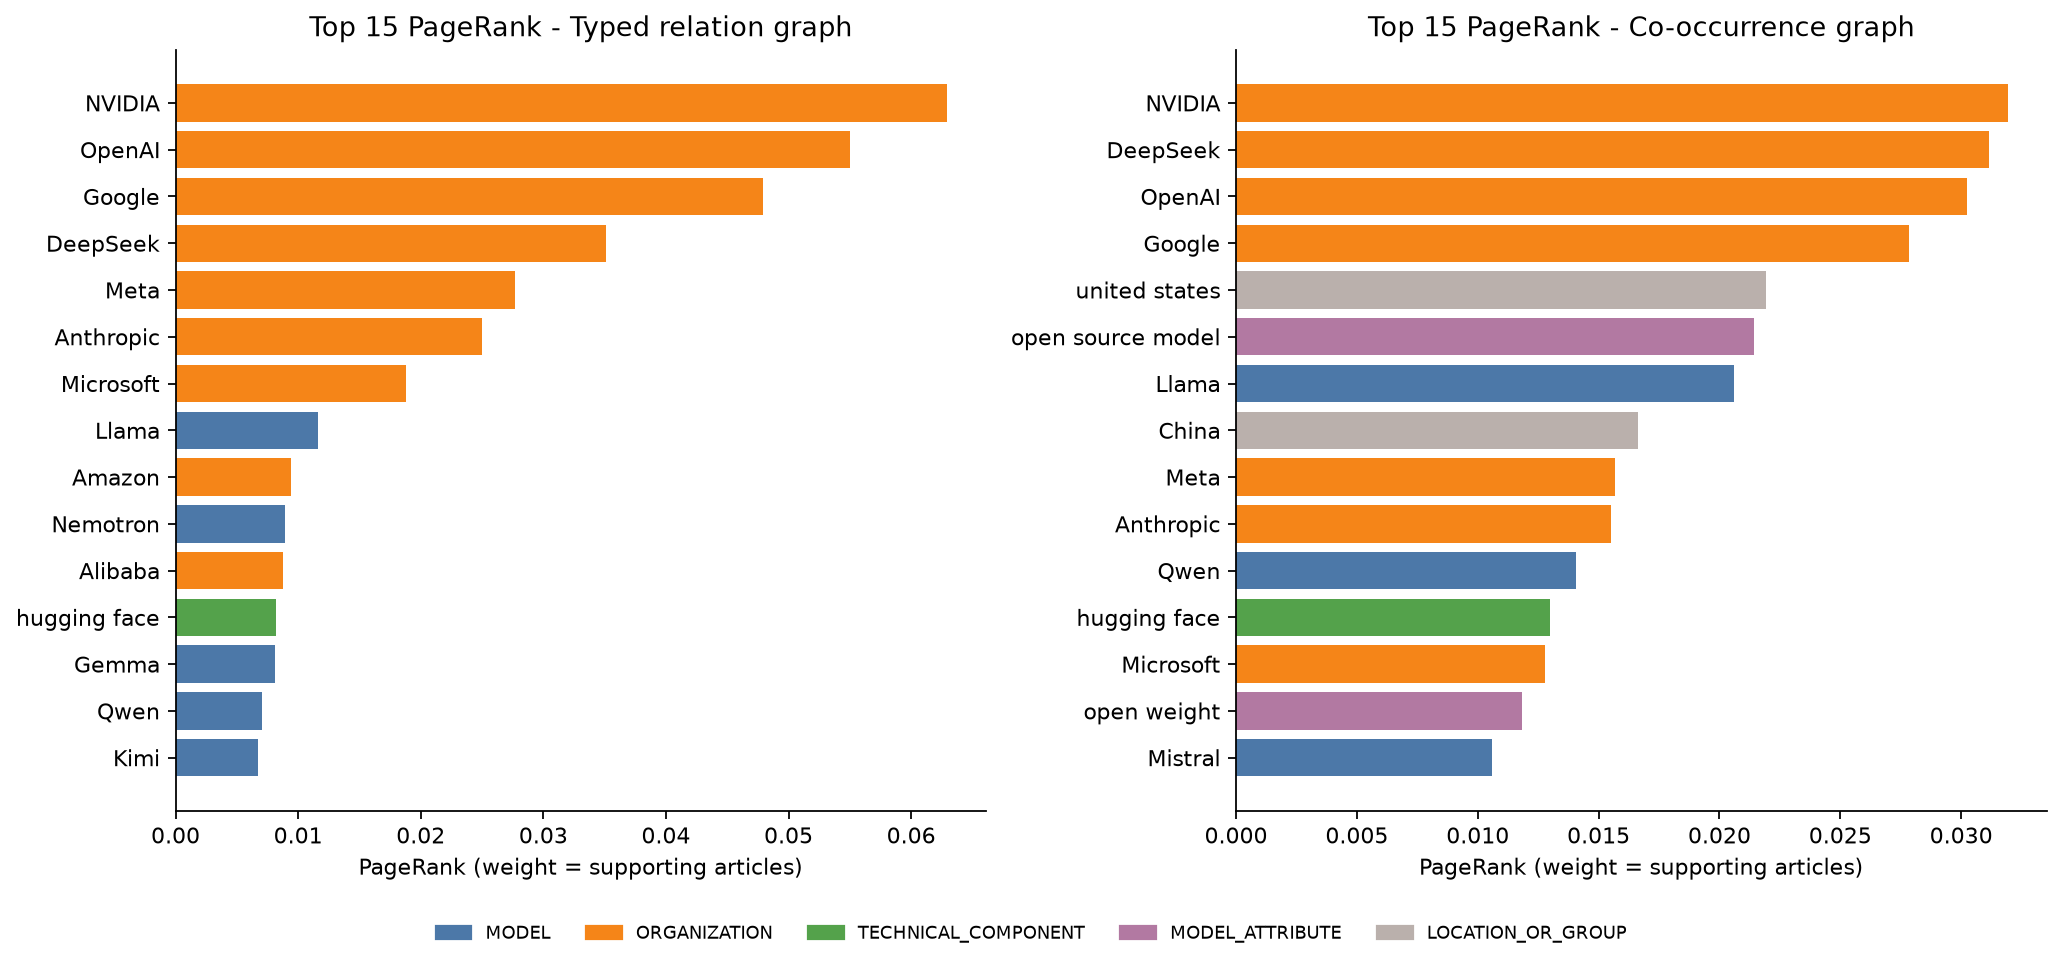

두 view의 PageRank 상위 20 중 겹치는 entity: 14개 -> Anthropic, China, DeepSeek, Gemini, Gemma, Google, Llama, Meta, Microsoft, Mistral, NVIDIA, OpenAI, Qwen, hugging_face


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metrics, title in [(axes[0], typed_metrics, "Typed relation graph"),
                           (axes[1], cooc_metrics, "Co-occurrence graph")]:
    top = metrics.head(15).iloc[::-1]
    ax.barh(top["canonical_name"].map(pretty), top["pagerank"], color=top["entity_type_compact"].map(COMPACT_COLORS))
    ax.set(title=f"Top 15 PageRank - {title}", xlabel="PageRank (weight = supporting articles)")
present = set(typed_metrics.head(15)["entity_type_compact"]) | set(cooc_metrics.head(15)["entity_type_compact"])
fig.legend(handles=[Patch(color=COMPACT_COLORS[t], label=t) for t in COMPACT_COLORS if t in present],
           loc="lower center", ncol=len(present), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "02_pagerank_typed_vs_cooccurrence.png")

overlap = set(typed_metrics.head(20)["entity_id"]) & set(cooc_metrics.head(20)["entity_id"])
print(f"두 view의 PageRank 상위 20 중 겹치는 entity: {len(overlap)}개 -> "
      + ", ".join(sorted(node_index.loc[list(overlap), "canonical_name"])))

**해석 (팀 검토 전 초안)**

- typed graph의 PageRank 상위 7개는 NVIDIA, OpenAI, Google, DeepSeek, Meta, Anthropic, Microsoft로 모두
  조직이다. 모델 family 중에서는 Llama, Nemotron, Gemma, Qwen, Kimi가 상위 15위 안에 든다.
- NVIDIA가 1위인 이유는 방향을 보면 설명된다. `developed by` in-degree가 83으로 가장 크다(Nemotron,
  DGX Spark, NemoClaw, Blackwell architecture 등). 하드웨어 공급자이면서 모델·소프트웨어 개발사로 가장 많은
  산출물과 연결되어 있다.
- OpenAI는 weighted degree(880)와 betweenness(0.30)가 가장 크다. 주로 `competes with`를 통해 여러 조직·모델을
  잇는 위치에 있다.
- co-occurrence graph에서는 `United States`, `China`, `open source model`처럼 맥락을 나타내는 entity가 상위에
  들어온다. 같은 문장에 함께 쓰인 빈도라서 담론의 배경(미·중 경쟁, open vs closed 논쟁)을 반영한다.
- 두 view의 PageRank 상위 20 중 14개가 겹쳐, **핵심 행위자 집합**은 view에 덜 민감하다. 그러나 18절에서 본
  것처럼 **순위**는 threshold에 따라 바뀌므로 산업 영향력 순위로 표현하지 않는다.

## 29. Clustering과 community

**왜**: 함께 언급되는 entity 묶음은 담론의 하위 주제(예: 중국 오픈 모델, NVIDIA 하드웨어 생태계)를
보여 준다. clustering coefficient는 triangle이 많은 co-occurrence graph에서 의미가 있고, 희소한 typed
graph에서는 낮게 나오는 것이 정상이다. community는 문서 수를 weight로 한 greedy modularity로 찾는다.

In [28]:
clustering_table = pd.DataFrame(
    [
        ("typed (undirected projection)", nx.average_clustering(typed_undirected), np.nan,
         nx.transitivity(typed_undirected)),
        ("co-occurrence", nx.average_clustering(cooccurrence_graph),
         nx.average_clustering(cooccurrence_graph, weight="document_count"), nx.transitivity(cooccurrence_graph)),
    ],
    columns=["view", "average clustering", "weighted average clustering", "transitivity"],
).round(4)
display(clustering_table)

community_members, community_summary = detect_cooccurrence_communities(cooccurrence_graph)
community_sets = [set(group["entity_id"]) for _, group in community_members.groupby("community_id")]
modularity = nx.community.modularity(cooccurrence_graph, community_sets, weight="document_count")
community_summary["top_entities"] = community_summary["top_entities"].map(lambda v: ", ".join(json.loads(v)[:8]))
community_summary["share_of_nodes"] = (community_summary["node_count"] / cooccurrence_graph.number_of_nodes()).round(3)
print(f"community {len(community_summary)}개 | modularity {modularity:.3f}")
display(community_summary.head(10))

,view,average clustering,weighted average clustering,transitivity
0,typed (undirected projection),0.0980,NaN,0.0689
1,co-occurrence,0.5409,0.008,0.0776


community 192개 | modularity 0.236


,community_id,node_count,edge_count,top_entities,share_of_nodes
0,1,1666,6739,"OpenAI, Google, open_source_model, Llama, Anth...",0.343
1,2,1338,3899,"united_states, DeepSeek, China, NVIDIA, Micros...",0.275
2,3,896,3582,"vllm, Nemotron, Google Cloud, IBM, Dell Techno...",0.184
3,4,124,313,"TrueFoundry, observability, routing, reliabili...",0.026
4,5,97,162,"MLA, Grouped-Query Attention, Multi-Head Atten...",0.020
5,6,44,65,"Facebook, Instagram, WhatsApp, Discord, Messen...",0.009
6,7,29,36,"MLLM, ControlNet, CLIP, T5-XXL, SD3, IP-Adapte...",0.006
7,8,16,32,"Kit, WebGPU, personality, Nico, Michael Knight...",0.003
8,9,16,49,"Arka Venture Labs, Astir VC, Good News Venture...",0.003
9,10,15,27,"Liquid AI, LFMs, Liquid, liquid neural network...",0.003


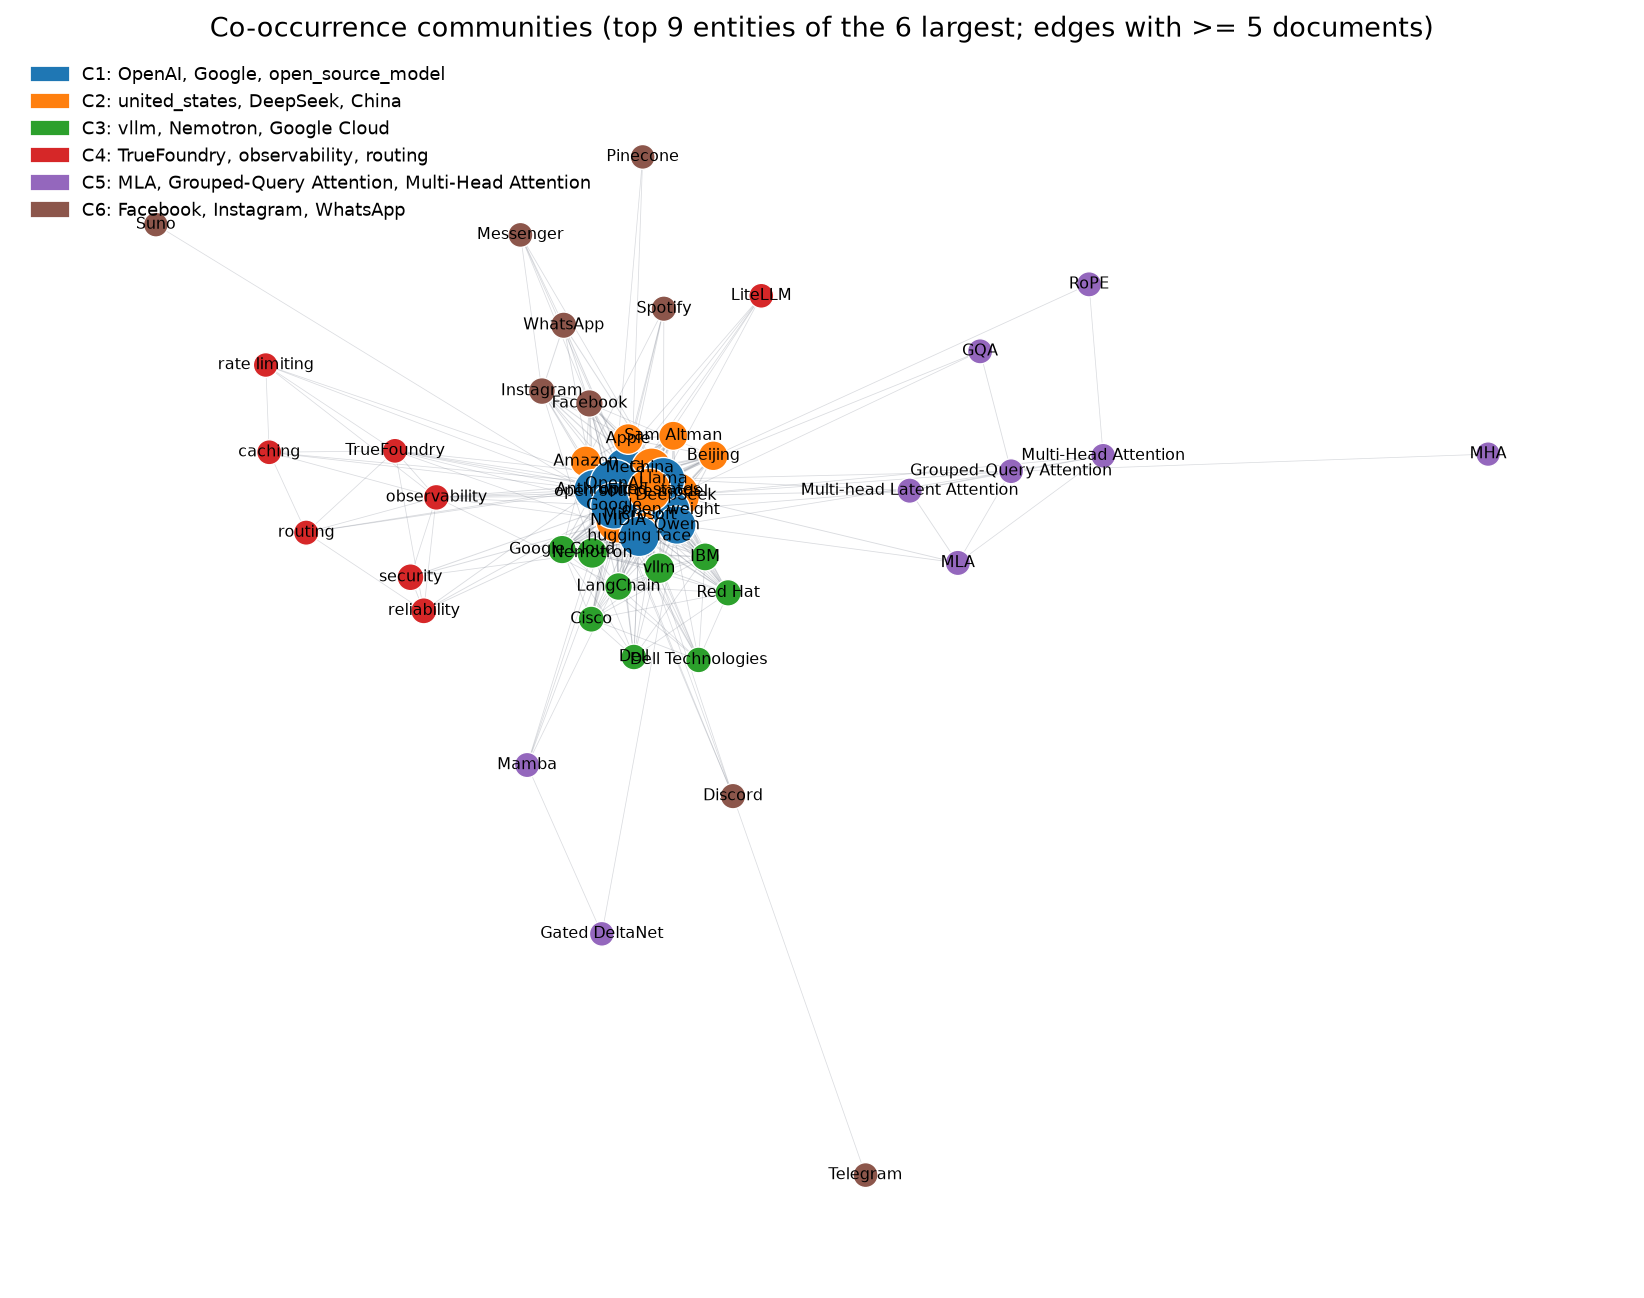

In [29]:
TOP_COMMUNITIES = 6
NODES_PER_COMMUNITY = 9
top_members = community_members[
    (community_members["community_id"] <= TOP_COMMUNITIES)
    & (community_members["rank_in_community"] <= NODES_PER_COMMUNITY)
]
draw = cooccurrence_graph.subgraph(top_members["entity_id"]).copy()
draw.remove_edges_from([(a, b) for a, b, d in draw.edges(data=True)
                        if d["document_count"] < DRAW_COOCCURRENCE_DOCUMENTS])
draw.remove_nodes_from(list(nx.isolates(draw)))
community_of = top_members.set_index("entity_id")["community_id"]
palette = plt.get_cmap("tab10")
positions = nx.spring_layout(draw, seed=SEED, weight="document_count", k=2.4 / np.sqrt(max(len(draw), 1)), iterations=500)
fig, ax = plt.subplots(figsize=(13, 10))
widths = [0.3 + 2.5 * d["document_count"] / max(nx.get_edge_attributes(draw, "document_count").values())
          for _, _, d in draw.edges(data=True)]
nx.draw_networkx_edges(draw, positions, width=widths, alpha=0.25, edge_color="#6B7280", ax=ax)
nx.draw_networkx_nodes(draw, positions, ax=ax, linewidths=0.6, edgecolors="white",
                       node_color=[palette(community_of[n] - 1) for n in draw],
                       node_size=[120 + 0.6 * draw.nodes[n]["document_count"] for n in draw])
nx.draw_networkx_labels(draw, positions, labels={n: pretty(draw.nodes[n]["label"]) for n in draw}, font_size=7, ax=ax)
legend_labels = community_summary.set_index("community_id")["top_entities"]
ax.legend(handles=[Patch(color=palette(c - 1), label=f"C{c}: " + ", ".join(legend_labels[c].split(", ")[:3]))
                   for c in range(1, TOP_COMMUNITIES + 1)], loc="upper left", frameon=False, fontsize=8)
ax.set_title(f"Co-occurrence communities (top {NODES_PER_COMMUNITY} entities of the {TOP_COMMUNITIES} largest; "
             f"edges with >= {DRAW_COOCCURRENCE_DOCUMENTS} documents)")
ax.axis("off")
save_figure(fig, "03_cooccurrence_communities.png")

**해석 (팀 검토 전 초안)**

- 평균 clustering은 co-occurrence graph가 0.54, typed graph가 0.10이다. 공동출현은 한 기사 안의 여러 entity가
  서로 묶여 triangle이 많고, typed graph는 모델 → 개발사처럼 별 모양 구조라 낮게 나오는 것이 정상이다.
- greedy modularity로 192개 community를 찾았고 modularity는 0.236이다. 값이 낮은 것은 주요 조직·모델이
  대부분의 기사에서 함께 언급되어 경계가 뚜렷하지 않기 때문이다.
- 그래도 상위 3개 community(전체 node의 약 80%)는 해석 가능한 담론 묶음으로 보인다.
  - **C1 (34%)** OpenAI, Google, open source model, Llama, Anthropic: 미국 frontier lab과 open vs closed 모델 논의
  - **C2 (28%)** United States, DeepSeek, China, NVIDIA, Microsoft: DeepSeek 이후 미·중 경쟁, 칩, 수출 통제 담론
  - **C3 (18%)** vLLM, Nemotron, Google Cloud, IBM, Dell: 기업용 배포·추론 인프라
  - 작은 community는 특정 기사 주제다: LLM gateway 운영(C4), attention 구조(C5: MLA, GQA), Meta 앱(C6).
- community 이름은 상위 entity를 보고 붙인 해석이므로 팀 검토 대상이다.

## 30. 시간 분석

모든 날짜는 기사 발행일이므로 "그 시점에 데이터셋에서 관찰된 관계"로 해석한다.

1. 분기별 relation 근거 문장 수 (predicate group별)
2. 분기별 새로 처음 관찰된 typed triple 수
3. 주요 open model family의 분기별 언급 기사 비율 (WP2 `nodes_quarterly`)
4. 2026년에 처음 관찰된 relation (emerging relationship 후보)
5. 전반기(P1)와 후반기(P2) 사이 relation 근거 비중이 가장 크게 늘어난 entity

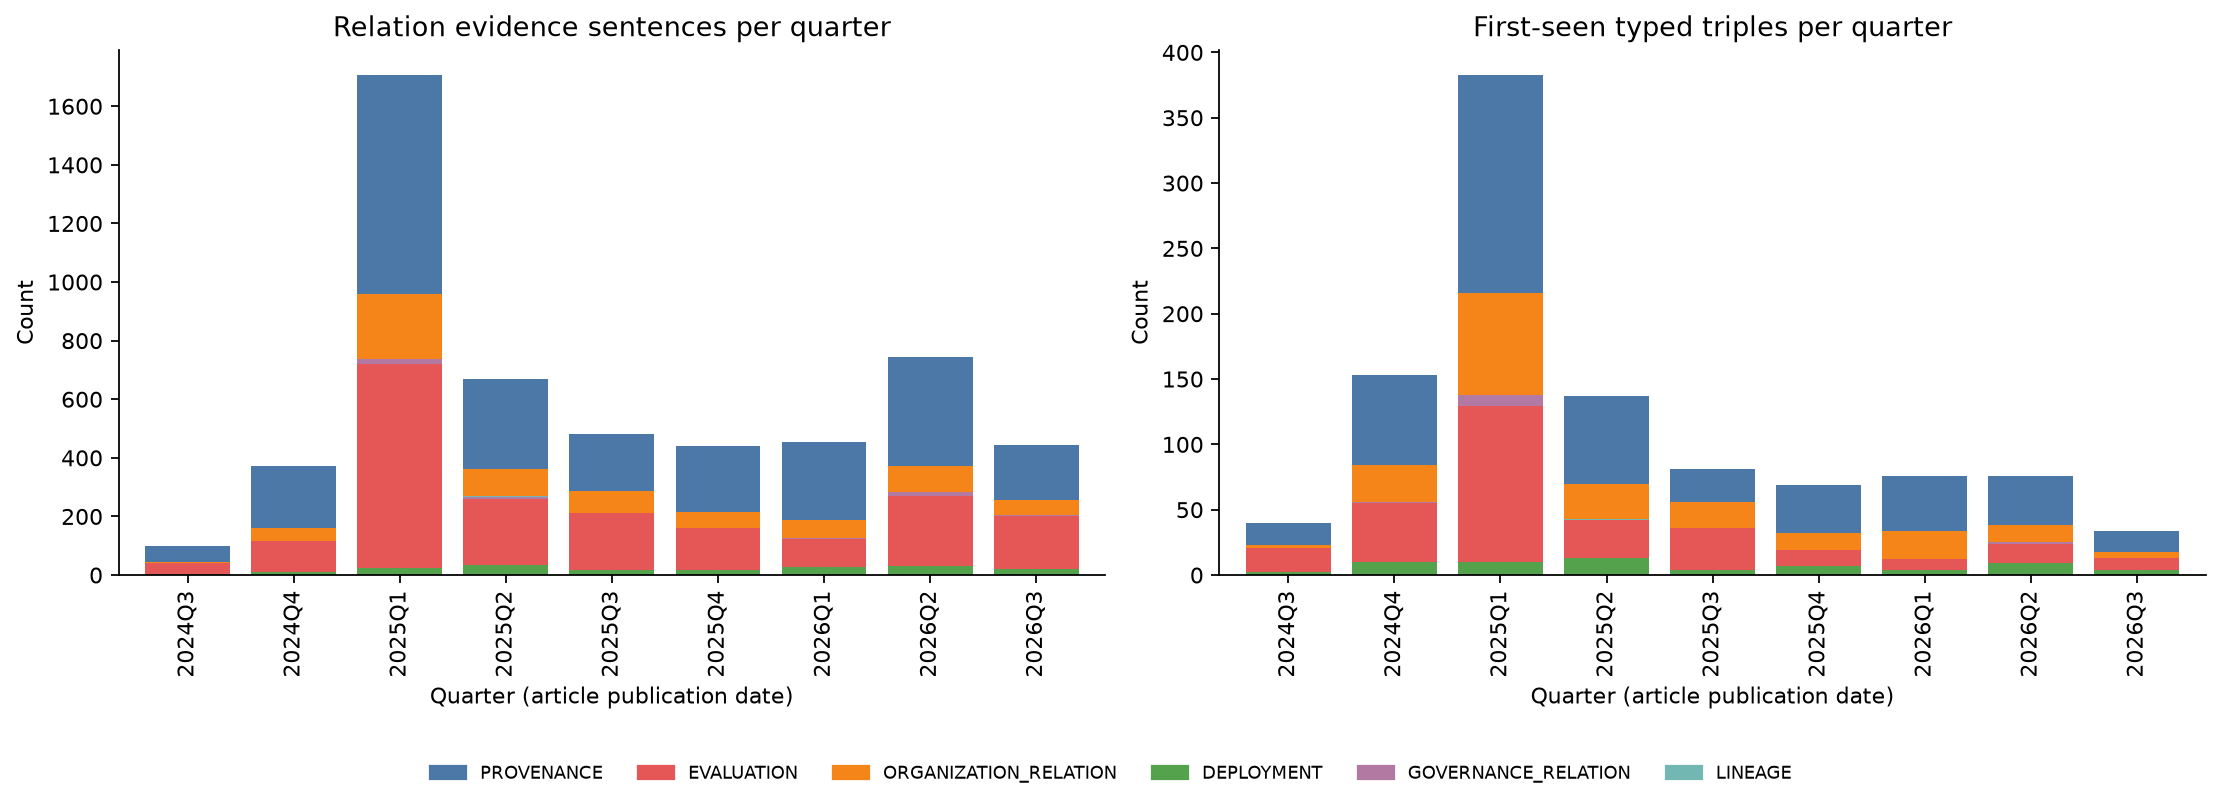

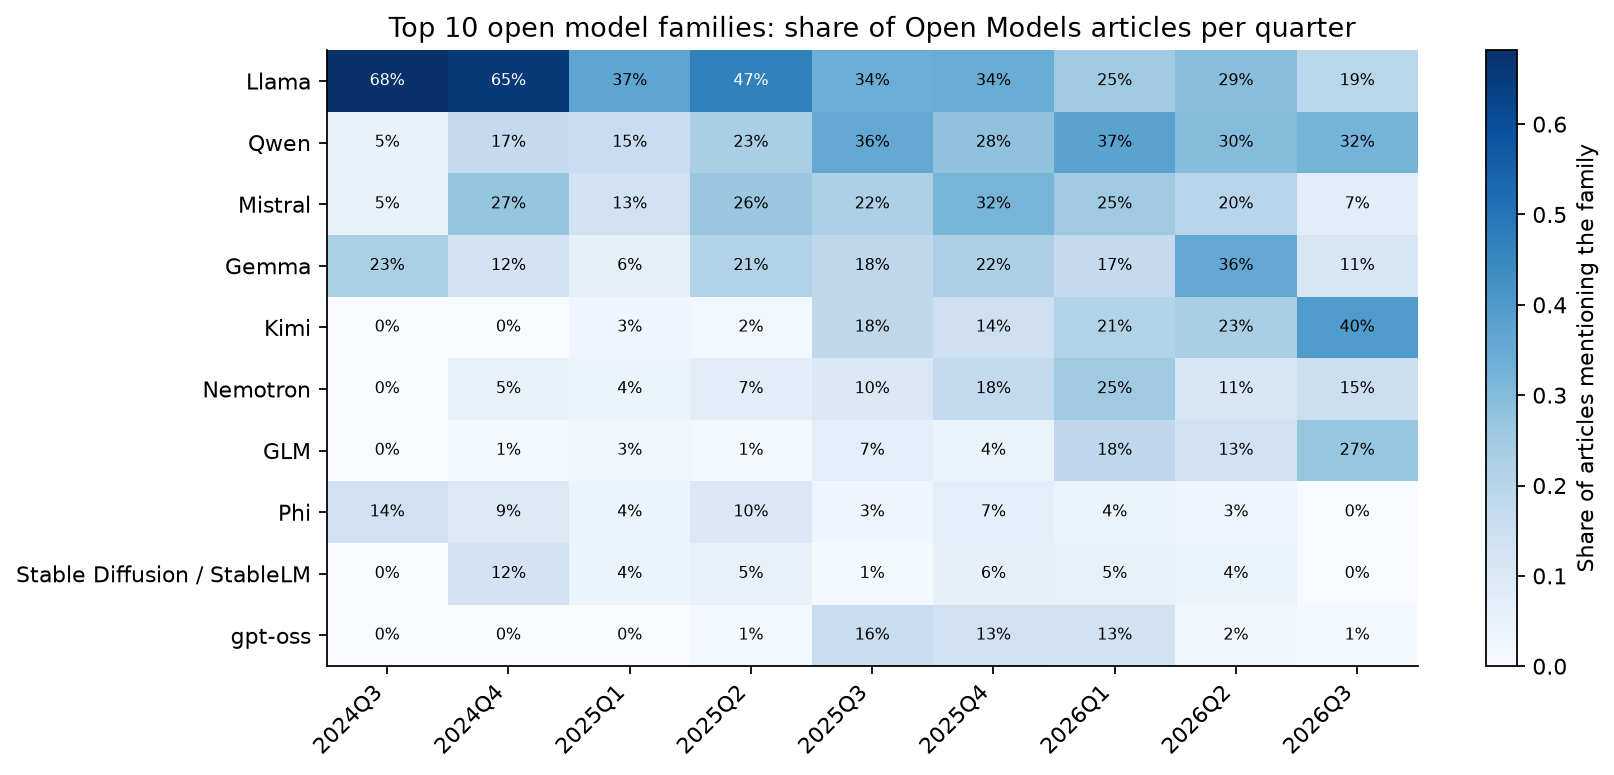

quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
기사 수,22,104,349,156,103,90,99,179,108


In [30]:
dated = assertions[assertions["extraction_method"] == "glirel"].copy()
dated["quarter"] = pd.to_datetime(dated["published_at"]).dt.to_period("Q").astype(str)
dated["predicate_group"] = dated["predicate"].map(PREDICATE_GROUP)
quarterly_assertions = dated.pivot_table(index="quarter", columns="predicate_group", values="relation_id",
                                         aggfunc="count", fill_value=0)

new_edges = collapsed[collapsed["first_seen"].notna()].copy()
new_edges["quarter"] = pd.to_datetime(new_edges["first_seen"]).dt.to_period("Q").astype(str)
quarterly_new_edges = new_edges.pivot_table(index="quarter", columns="predicate_group", values="predicate",
                                            aggfunc="count", fill_value=0)

mentions = pd.read_csv(WP2_INPUT_DIR / "entity_mentions.csv", usecols=["doc_id", "quarter"])
documents_per_quarter = mentions.drop_duplicates("doc_id")["quarter"].value_counts().sort_index()
families = nodes_kg[nodes_kg["is_open_model_family"]].set_index("entity_id")["canonical_name"]
family_quarterly = nodes_quarterly.assign(entity_id=nodes_quarterly["entity_id"].map(id_map))
family_quarterly = (family_quarterly[family_quarterly["entity_id"].isin(families.index)]
                    .groupby(["entity_id", "quarter"])["n_docs"].sum().unstack(fill_value=0))
family_share = family_quarterly.div(documents_per_quarter.reindex(family_quarterly.columns), axis=1)
top_families = family_quarterly.sum(axis=1).nlargest(10).index
family_share = family_share.loc[top_families].rename(index=families)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], quarterly_assertions, "Relation evidence sentences per quarter"),
                         (axes[1], quarterly_new_edges, "First-seen typed triples per quarter")]:
    table.plot(ax=ax, kind="bar", stacked=True, width=0.8,
               color=[GROUP_COLORS.get(c, "#BAB0AC") for c in table.columns], legend=False)
    ax.set(title=title, xlabel="Quarter (article publication date)", ylabel="Count")
handles = [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS if g in set(quarterly_assertions.columns)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "04_quarterly_relations.png")

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(family_share.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(family_share.shape[1]), family_share.columns, rotation=45, ha="right")
ax.set_yticks(range(family_share.shape[0]), family_share.index)
for (i, j), value in np.ndenumerate(family_share.values):
    ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
            color="white" if value > family_share.values.max() * 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of articles mentioning the family")
ax.set_title("Top 10 open model families: share of Open Models articles per quarter")
save_figure(fig, "05_family_quarterly_share.png")
display(documents_per_quarter.rename("기사 수").to_frame().T)

In [31]:
labels = node_index["canonical_name"]
emerging = collapsed[(collapsed["first_seen"].fillna("") >= "2026-01-01") & (collapsed["document_count"] >= 2)].copy()
emerging["edge"] = emerging["subject_id"].map(labels) + " -> " + emerging["predicate"] + " -> " + emerging["object_id"].map(labels)
print(f"2026년에 처음 관찰되고 2개 이상 기사로 뒷받침되는 triple: {len(emerging)}개")
display(emerging.sort_values(["document_count", "first_seen"], ascending=[False, True])
        .head(15)[["edge", "predicate_group", "document_count", "first_seen", "last_seen"]])

def period_share(start, end):
    rows = dated[(dated["published_at"] >= start) & (dated["published_at"] <= end)]
    long = pd.concat([rows[["subject_id", "document_id"]].rename(columns={"subject_id": "entity_id"}),
                      rows[["object_id", "document_id"]].rename(columns={"object_id": "entity_id"})])
    per_entity = long.drop_duplicates().groupby("entity_id")["document_id"].nunique()
    return per_entity / rows["document_id"].nunique()

shares = pd.DataFrame({name: period_share(*span) for name, span in PERIODS.items()}).fillna(0)
p1, p2 = shares.columns
shares["change_pp"] = (shares[p2] - shares[p1]) * 100
shares["canonical_name"] = shares.index.map(labels)
shares["entity_type_compact"] = shares.index.map(node_index["entity_type_compact"])
print("relation 근거 기사 비중 변화 (P2 - P1, %p)")
display(pd.concat([shares.nlargest(10, "change_pp"), shares.nsmallest(5, "change_pp")])
        [["canonical_name", "entity_type_compact", p1, p2, "change_pp"]].round(3))

2026년에 처음 관찰되고 2개 이상 기사로 뒷받침되는 triple: 125개


,edge,predicate_group,document_count,first_seen,last_seen
634,NemoClaw -> developed by -> NVIDIA,PROVENANCE,9,2026-03-11,2026-08-11
15,Latent Space -> acquired by -> AINews,ORGANIZATION_RELATION,8,2026-03-25,2026-05-28
456,Muse Spark -> developed by -> Meta,PROVENANCE,7,2026-04-08,2026-07-24
84,GLM -> competes with -> Anthropic,EVALUATION,5,2026-06-25,2026-08-19
764,Anthropic -> headquartered in -> China,ORGANIZATION_RELATION,4,2026-02-04,2026-08-07
565,AI Gateway -> developed by -> TrueFoundry,PROVENANCE,4,2026-03-02,2026-06-04
551,OpenClaw -> developed by -> NVIDIA,PROVENANCE,4,2026-03-11,2026-04-30
684,hugging_face -> developed by -> Google DeepMind,PROVENANCE,4,2026-03-11,2026-06-10
553,OpenShell -> developed by -> NVIDIA,PROVENANCE,4,2026-03-16,2026-07-27
460,Mythos -> developed by -> Anthropic,PROVENANCE,4,2026-04-04,2026-06-12


relation 근거 기사 비중 변화 (P2 - P1, %p)


,canonical_name,entity_type_compact,P1 (2024-09~2025-08),P2 (2025-09~2026-08),change_pp
entity_id,,,,,
org:anthropic,Anthropic,ORGANIZATION,0.142,0.291,14.913
model:nemotron,Nemotron,MODEL,0.044,0.143,9.914
model:kimi,Kimi,MODEL,0.027,0.102,7.433
org:nvidia,NVIDIA,ORGANIZATION,0.213,0.280,6.711
model:gemma,Gemma,MODEL,0.075,0.126,5.169
model:glm,GLM,MODEL,0.007,0.058,5.041
org:moonshot_ai,MoonShot AI,ORGANIZATION,0.015,0.060,4.587
org:google,Google,ORGANIZATION,0.321,0.357,3.656
hardware:dgx_spark,DGX Spark,INFRASTRUCTURE,0.007,0.033,2.568


**해석 (팀 검토 전 초안)**

- **2025Q1 집중**: relation 근거 문장이 약 1,700개로 다른 분기의 2~4배이고, 기사 수도 349개로 가장 많다
  (DeepSeek-R1 공개 직후). 처음 관찰된 triple도 이 분기에 가장 많다. 따라서 분기 비교는 기사 수로 정규화한
  지표(family 비율, 근거 기사 비중)를 우선한다.
- **family 담론의 이동**: Llama를 언급한 기사 비율은 2024Q3 68%에서 2026Q3 19%로 계속 낮아졌다. 반면 Qwen은
  5% → 30%대, Kimi는 0% → 40%(2026Q3), GLM은 0% → 27%로 올라갔다. Nemotron은 2026Q1에 25%로 가장 높았고,
  gpt-oss는 공개 직후인 2025Q3에 16%까지 올랐다가 줄었다.
- **relation 근거 비중 변화 (P1 → P2)**: Anthropic +14.9%p, Nemotron +9.9%p, Kimi +7.4%p, NVIDIA +6.7%p,
  GLM +5.0%p가 늘었고, DeepSeek −27.0%p, Meta −13.0%p, Llama −9.8%p가 줄었다. DeepSeek 감소는 2025Q1 집중 보도의
  반동으로 볼 수 있다.
- **2026년 신규 relation**: 125개 중 상위는 NemoClaw·OpenShell → NVIDIA(agent 소프트웨어), Muse Spark → Meta,
  GPT-5.5 → OpenAI, Claude Mythos 5·Fable 5 → Anthropic이다. 다만 `Anthropic → headquartered in → China`,
  `hugging_face → developed by → Google DeepMind`처럼 명백한 오류도 섞여 있다. **Tier B에도 오류가 남아 있으므로**
  사람 검수 전에는 개별 relation을 사실로 인용하지 않는다.
- 2024Q3은 9월, 2026Q3은 7~8월만 포함한다. 날짜는 모두 기사 발행일이다.

## 31. 목적별 graph 시각화

전체 graph를 한 그림에 그리면 읽을 수 없으므로 질문별로 subgraph를 나눈다. 모든 그림에서 node 색은
compact entity type, edge 색은 predicate group이고, threshold는 제목에 적었다.

1. **핵심 typed graph**: typed PageRank 상위 entity 사이의 relation
2. **Open model family → developer**: lexicon(Tier A)과 기사 근거(Tier B)를 선 모양으로 구분
3. **경쟁·성능 비교**: `competes with`(점선, 방향 없음)와 `outperforms`(화살표)

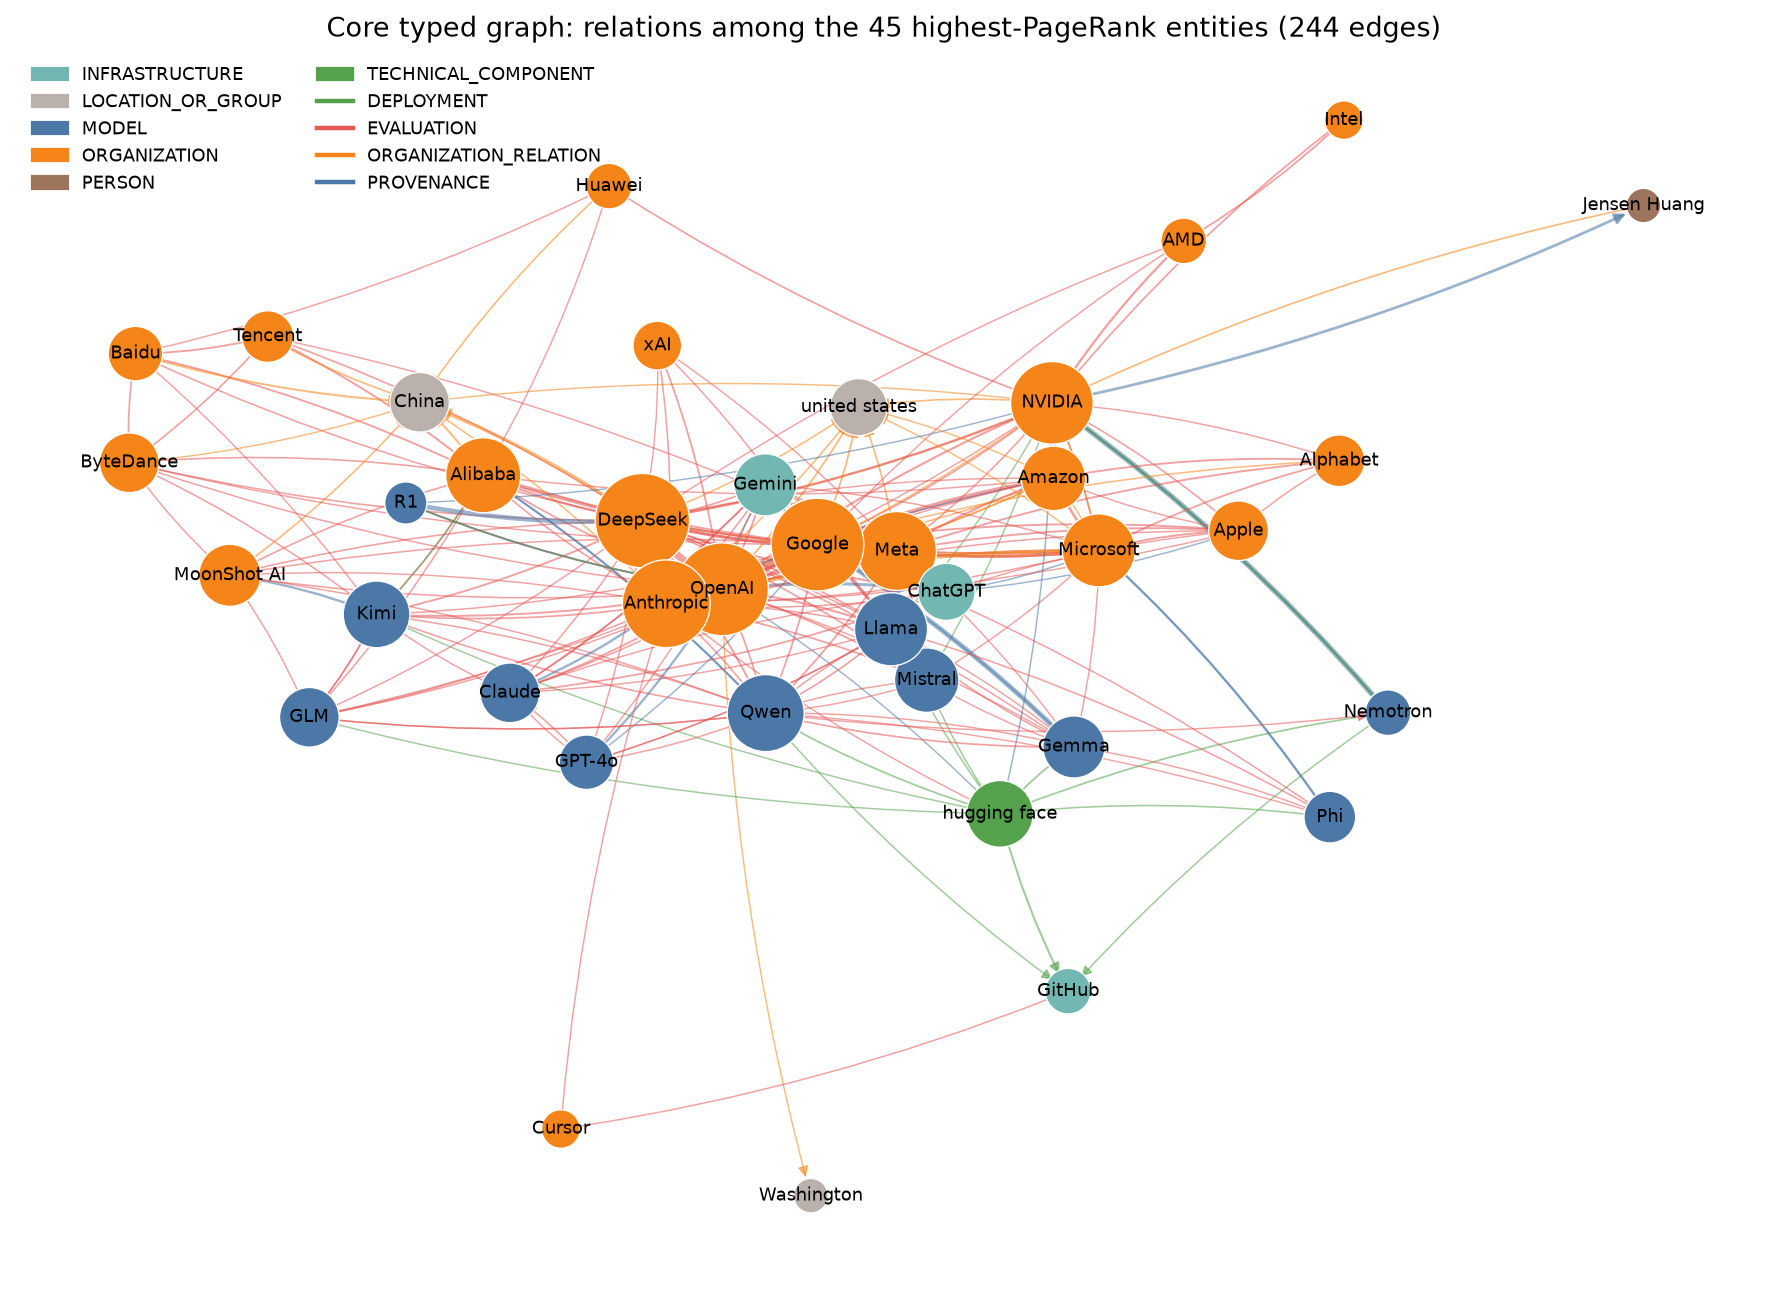

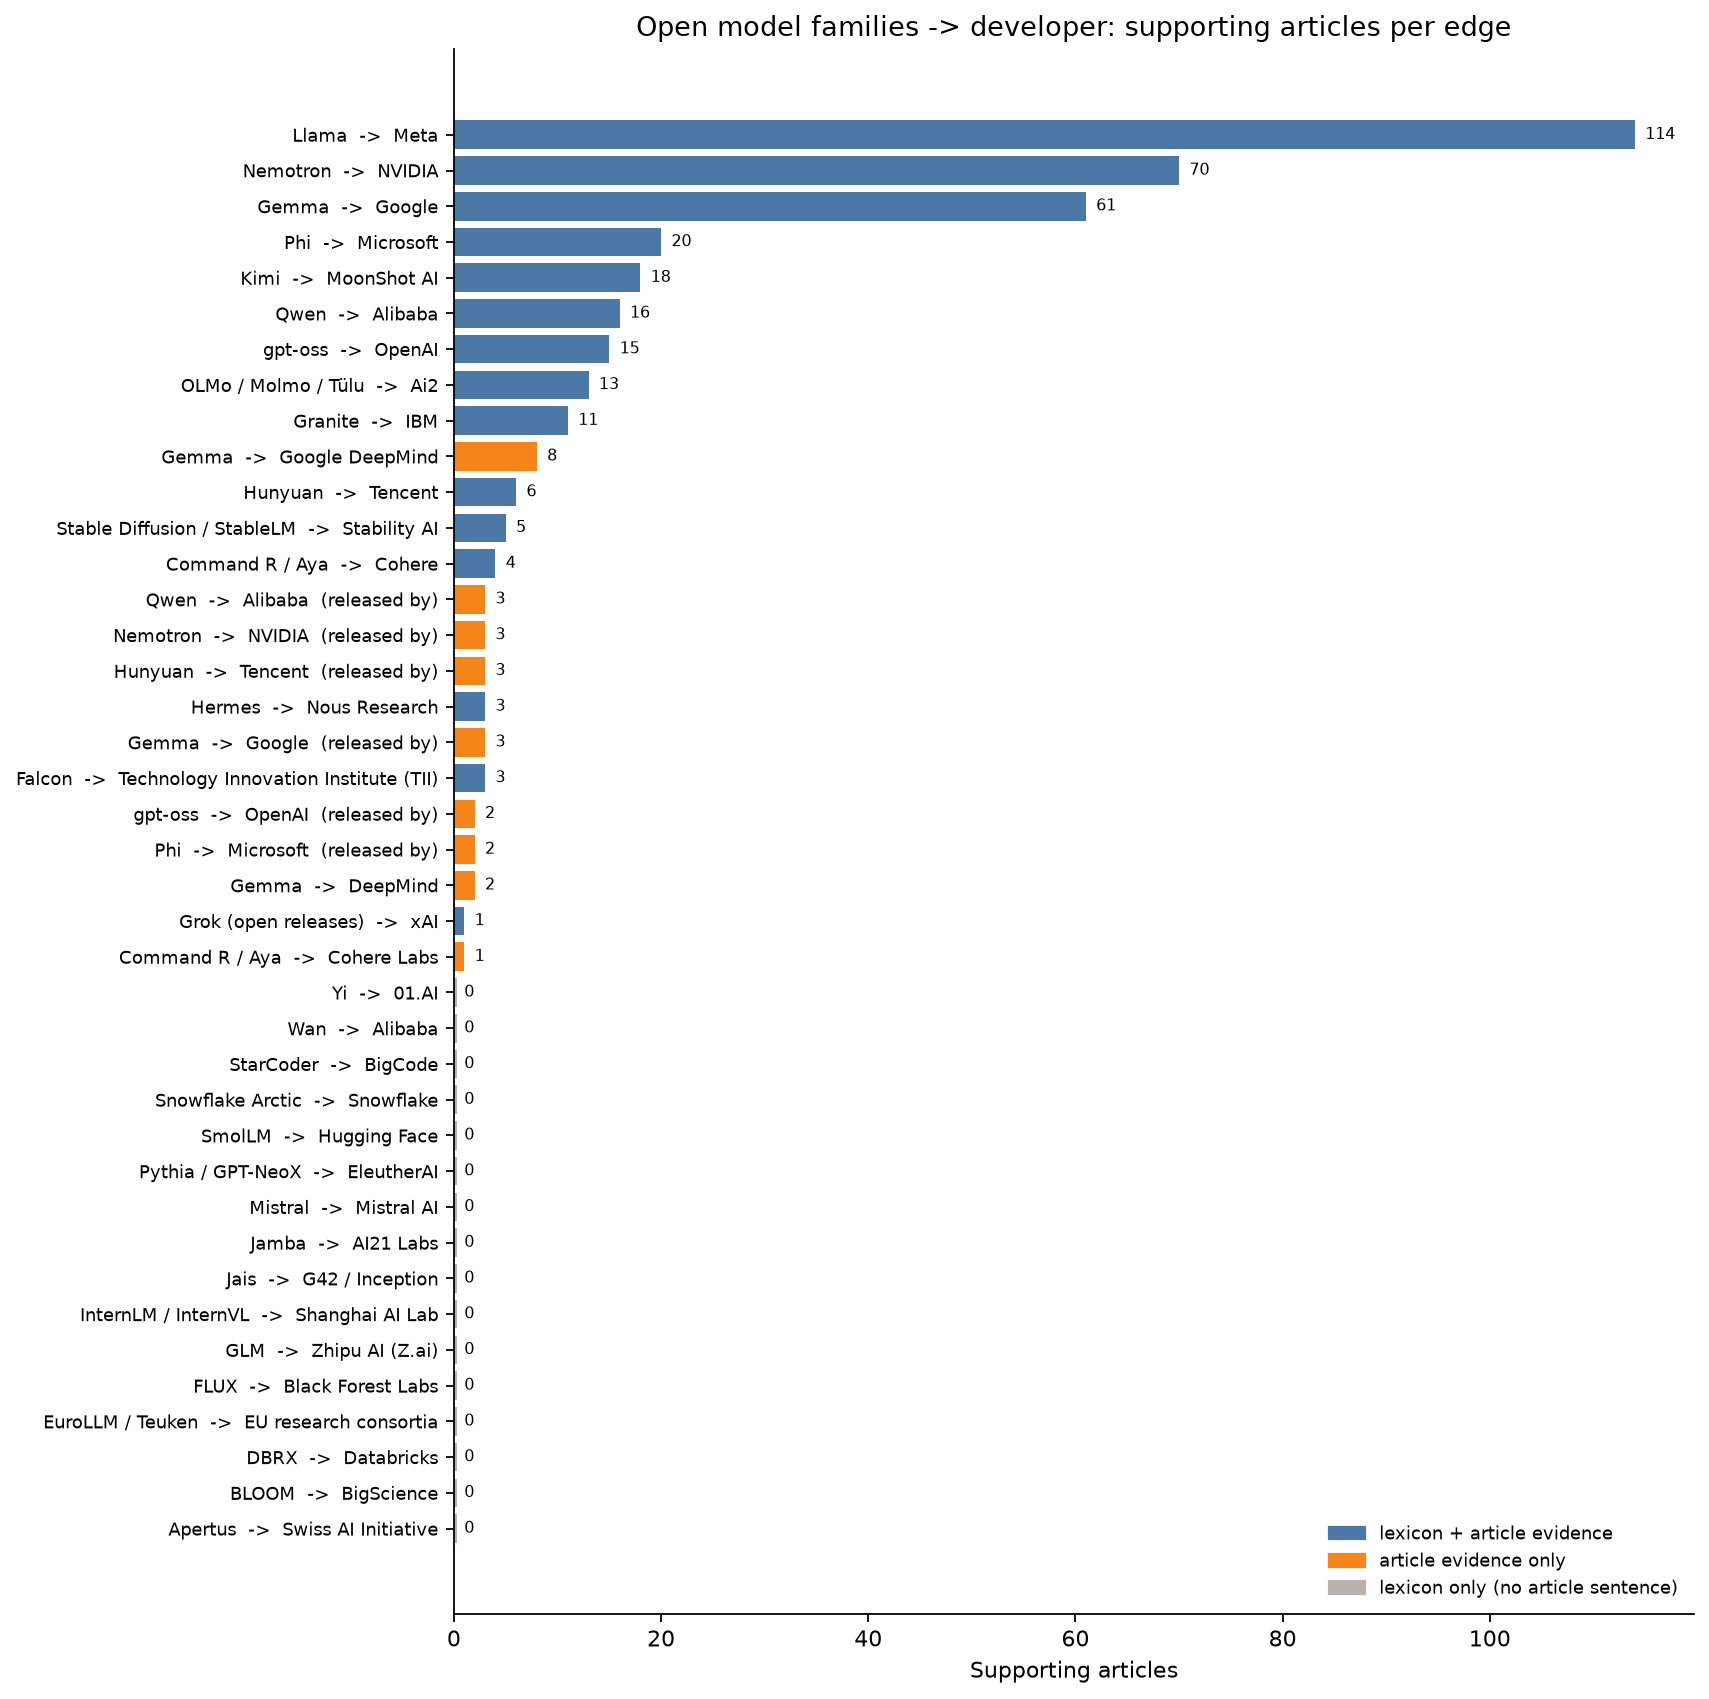

,근거 유형,edge 수
0,lexicon only (no article sentence),16
1,lexicon + article evidence,15
2,article evidence only,9


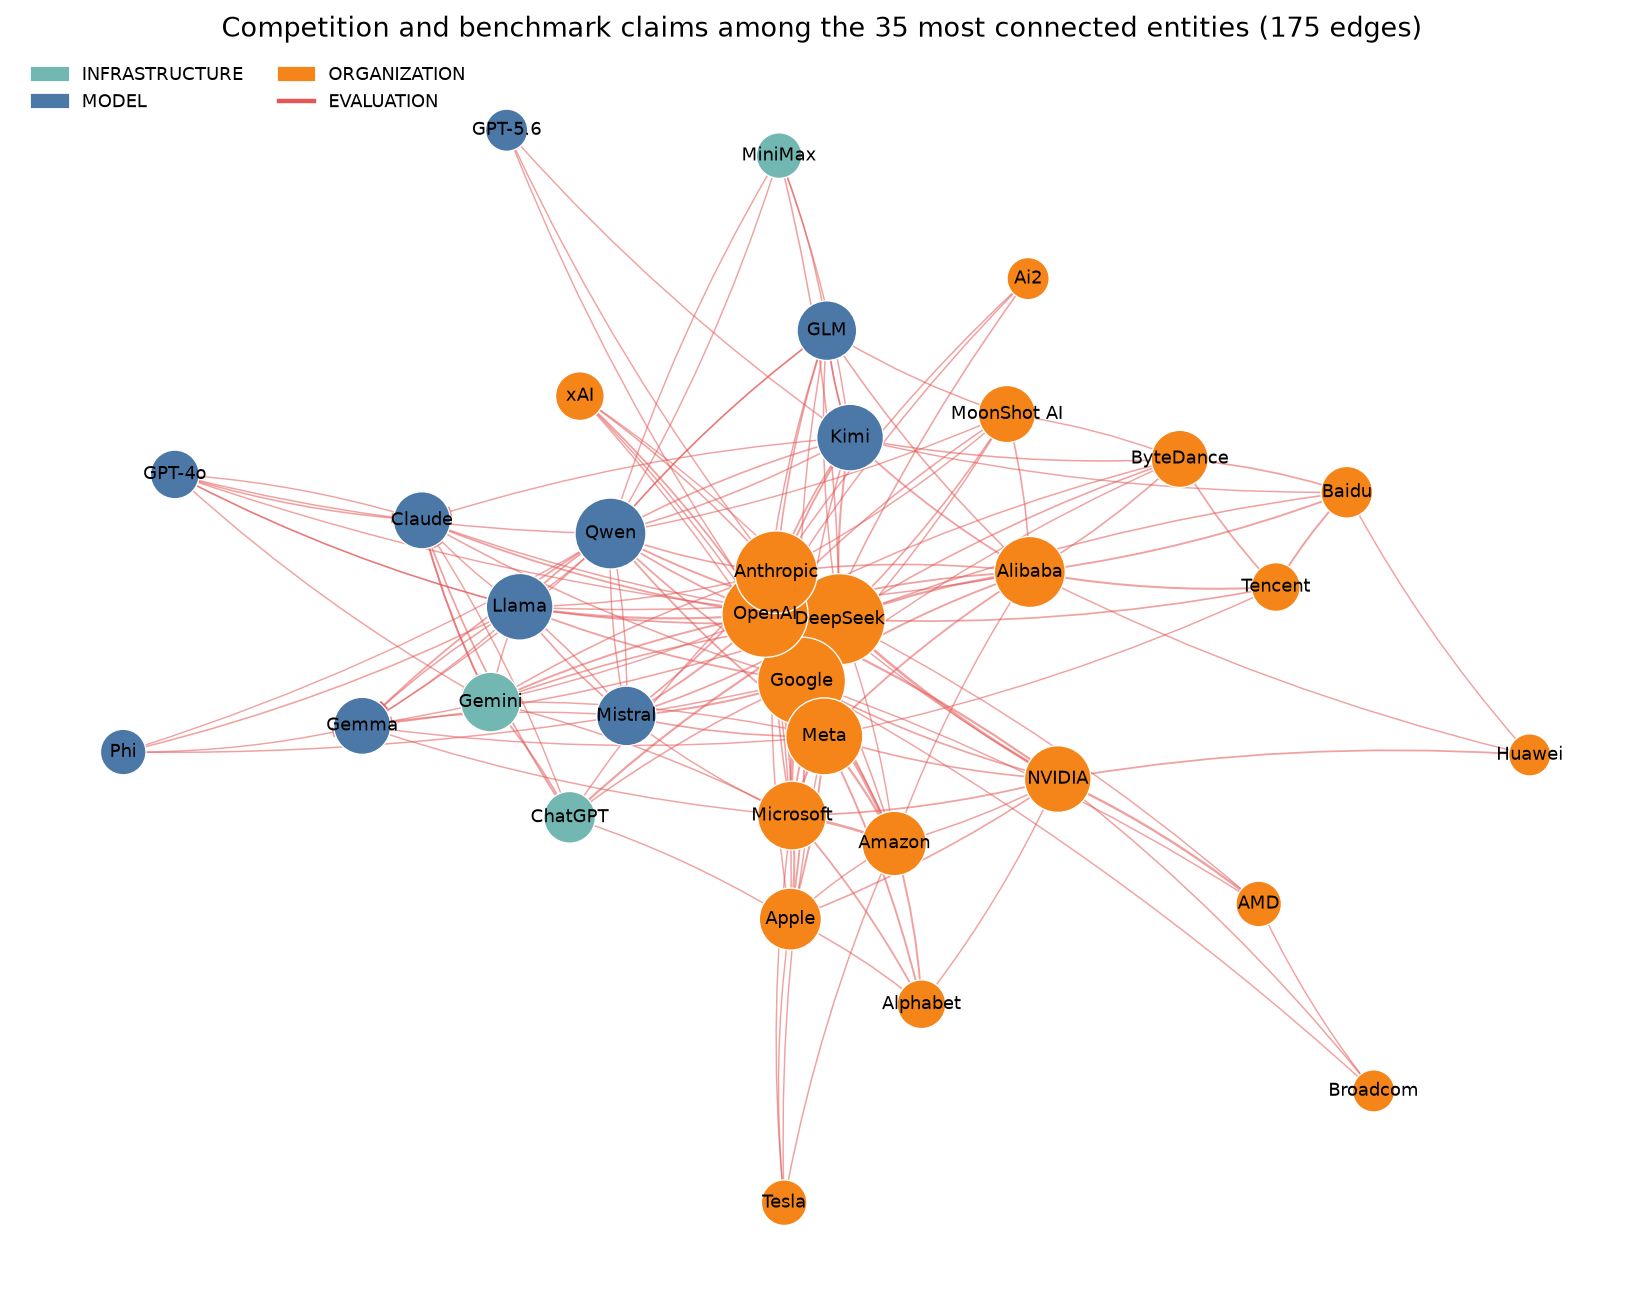

In [32]:
def draw_typed_subgraph(edges, title, filename, max_labels=40, figsize=(14, 10), k=None):
    graph = nx.MultiDiGraph()
    for row in edges.itertuples(index=False):
        for entity_id in (row.subject_id, row.object_id):
            graph.add_node(entity_id, label=labels[entity_id],
                           compact=node_index.loc[entity_id, "entity_type_compact"])
        graph.add_edge(row.subject_id, row.object_id, key=row.predicate, group=row.predicate_group,
                       weight=row.weight, directed=row.directed, sources=row.sources)
    simple = nx.Graph(graph.to_undirected())
    positions = nx.spring_layout(simple, seed=SEED, k=k or 1.6 / np.sqrt(len(simple)), iterations=400)
    fig, ax = plt.subplots(figsize=figsize)
    max_weight = max(d["weight"] for _, _, d in graph.edges(data=True))
    for source, target, data in graph.edges(data=True):
        nx.draw_networkx_edges(
            graph, positions, edgelist=[(source, target)], ax=ax, width=0.6 + 3.0 * data["weight"] / max_weight,
            edge_color=GROUP_COLORS.get(data["group"], "#6B7280"), alpha=0.55,
            style="solid" if "glirel" in data["sources"] else "dashed",
            arrows=True, arrowstyle="-|>" if data["directed"] else "-", arrowsize=10,
            connectionstyle="arc3,rad=0.06", node_size=300)
    degree = dict(simple.degree())
    nx.draw_networkx_nodes(graph, positions, ax=ax, linewidths=0.6, edgecolors="white",
                           node_color=[COMPACT_COLORS[graph.nodes[n]["compact"]] for n in graph],
                           node_size=[180 + 60 * degree[n] for n in graph])
    shown = sorted(graph, key=lambda n: -degree[n])[:max_labels]
    nx.draw_networkx_labels(graph, positions, labels={n: pretty(graph.nodes[n]["label"]) for n in shown}, font_size=8, ax=ax)
    groups = sorted({d["group"] for _, _, d in graph.edges(data=True)})
    types = sorted({graph.nodes[n]["compact"] for n in graph})
    handles = ([Patch(color=COMPACT_COLORS[t], label=t) for t in types]
               + [Line2D([0], [0], color=GROUP_COLORS[g], lw=2, label=g) for g in groups])
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=8, ncol=2)
    ax.set_title(title)
    ax.axis("off")
    save_figure(fig, filename)

core_ids = set(typed_metrics.head(45)["entity_id"])
core_edges = collapsed[collapsed["subject_id"].isin(core_ids) & collapsed["object_id"].isin(core_ids)]
draw_typed_subgraph(core_edges, f"Core typed graph: relations among the 45 highest-PageRank entities ({len(core_edges)} edges)",
                    "06_core_typed_graph.png")

family_ids = set(nodes_kg.loc[nodes_kg["is_open_model_family"], "entity_id"])
family_edges = collapsed[collapsed["subject_id"].isin(family_ids)
                         & collapsed["predicate"].isin(["developed by", "released by"])]
# Family -> developer pairs are mostly disconnected, so a ranked bar chart is clearer than a network layout.
family_plot = family_edges.assign(
    pair=family_edges["subject_id"].map(labels).map(pretty) + "  ->  " + family_edges["object_id"].map(labels).map(pretty)
         + np.where(family_edges["predicate"].eq("released by"), "  (released by)", ""),
    evidence=np.select(
        [family_edges["sources"].str.contains("glirel") & family_edges["sources"].str.contains("wp1_lexicon"),
         family_edges["sources"].str.contains("glirel")],
        ["lexicon + article evidence", "article evidence only"], default="lexicon only (no article sentence)"),
).sort_values(["document_count", "pair"]).reset_index(drop=True)
EVIDENCE_COLORS = {"lexicon + article evidence": "#4C78A8", "article evidence only": "#F58518",
                   "lexicon only (no article sentence)": "#BAB0AC"}
fig, ax = plt.subplots(figsize=(10, 0.28 * len(family_plot) + 1.5))
ax.barh(family_plot["pair"], family_plot["document_count"].clip(lower=0.3),
        color=family_plot["evidence"].map(EVIDENCE_COLORS))
for y, value in enumerate(family_plot["document_count"]):
    ax.text(value + 1, y, str(int(value)), va="center", fontsize=7)
ax.legend(handles=[Patch(color=c, label=l) for l, c in EVIDENCE_COLORS.items()], loc="lower right", frameon=False, fontsize=8)
ax.set(title="Open model families -> developer: supporting articles per edge", xlabel="Supporting articles", ylabel="")
ax.tick_params(axis="y", labelsize=8)
save_figure(fig, "07_family_developer_edges.png")
display(family_plot["evidence"].value_counts().rename_axis("근거 유형").reset_index(name="edge 수"))

compete = collapsed[collapsed["predicate"].isin(["competes with", "outperforms"])]
compete_ids = set(pd.concat([compete["subject_id"], compete["object_id"]]).value_counts().head(35).index)
compete = compete[compete["subject_id"].isin(compete_ids) & compete["object_id"].isin(compete_ids)]
draw_typed_subgraph(compete, f"Competition and benchmark claims among the 35 most connected entities ({len(compete)} edges)",
                    "08_competition_graph.png", figsize=(13, 10))

## 32. Insight 후보와 근거 문장

graph pattern을 insight로 쓰기 전에 원문 근거와 대조해야 한다. 아래 표는 graph에서 자동으로 고른
후보이며, 각 후보에 근거 기사 수와 대표 근거 문장(점수가 가장 높은 문장, 기사 발행일 포함)을 붙인다.
`review_status=pending_team_review`이므로 팀 검토 전에는 확정된 결론이 아니다.

In [33]:
def evidence_examples(subject_id, predicate, object_id, n=1):
    rows = dated[(dated["subject_id"] == subject_id) & (dated["predicate"] == predicate) & (dated["object_id"] == object_id)]
    rows = rows.sort_values("rule_score", ascending=False).drop_duplicates("document_id").head(n)
    return " || ".join(f"[{r.published_at}] {str(r.evidence_text)[:220]}" for r in rows.itertuples(index=False))

findings = []
developers = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(5, "in_degree")
for row in developers.itertuples(index=False):
    products = collapsed[(collapsed["predicate"] == "developed by") & (collapsed["object_id"] == row.entity_id)]
    top = products.nlargest(4, "document_count")
    findings.append({"finding_type": "developer_hub", "entity_or_edge": row.canonical_name,
                     "metric": f"developed by in-degree {int(row.in_degree)}",
                     "documents": int(products["document_count"].sum()),
                     "detail": ", ".join(top["subject_id"].map(labels)),
                     "evidence": evidence_examples(top.iloc[0]["subject_id"], "developed by", row.entity_id)})
for predicate in ["competes with", "outperforms"]:
    for row in collapsed[collapsed["predicate"] == predicate].nlargest(4, "document_count").itertuples(index=False):
        findings.append({"finding_type": f"strong_{predicate.replace(' ', '_')}",
                         "entity_or_edge": f"{labels[row.subject_id]} -> {predicate} -> {labels[row.object_id]}",
                         "metric": "supporting articles", "documents": int(row.document_count),
                         "detail": f"{row.first_seen} ~ {row.last_seen}",
                         "evidence": evidence_examples(row.subject_id, predicate, row.object_id)})
for row in emerging.nlargest(5, "document_count").itertuples(index=False):
    findings.append({"finding_type": "emerging_2026", "entity_or_edge": row.edge, "metric": "first seen",
                     "documents": int(row.document_count), "detail": row.first_seen,
                     "evidence": evidence_examples(row.subject_id, row.predicate, row.object_id)})
for row in shares.nlargest(3, "change_pp").itertuples():
    findings.append({"finding_type": "rising_entity", "entity_or_edge": row.canonical_name,
                     "metric": f"relation evidence share {row.change_pp:+.1f}pp (P2 - P1)", "documents": None,
                     "detail": row.entity_type_compact, "evidence": ""})
finding_candidates = pd.DataFrame(findings).assign(review_status="pending_team_review")
with pd.option_context("display.max_colwidth", 160):
    display(finding_candidates)

,finding_type,entity_or_edge,metric,documents,detail,evidence,review_status
0,developer_hub,NVIDIA,developed by in-degree 83,314.0,"Nemotron, DGX Spark, NemoClaw, Blackwell architecture",[2025-08-14] NVIDIA-Nemotron-Nano-12B-v2-Base is a large language model (LLM) developed by NVIDIA that is designed as a completion model for a given piece o...,pending_team_review
1,developer_hub,Google,developed by in-degree 61,239.0,"Gemma, Gemini, ML Pathways, TPUs","[2026-06-10] Developed by Google DeepMind, DiffusionGemma undergoes the same rigorous safety evaluations as our proprietary Gemini models.",pending_team_review
2,developer_hub,OpenAI,developed by in-degree 51,333.0,"ChatGPT, GPT-5, o1, GPT-4",[2025-03-19] OpenAI has developed ChatGPT into one of the prominent alternatives to Le Chat.,pending_team_review
3,developer_hub,Anthropic,developed by in-degree 22,83.0,"Claude, MCP, Sonnet, Claude Code","[2026-03-25] Claude can now use your computer (Activity: 2106): Claude, an AI developed by Anthropic, is now capable of using your computer to perform tasks...",pending_team_review
4,developer_hub,DeepSeek,developed by in-degree 17,149.0,"R1, R1 model, Chinese AI, V3","[2025-01-27] The model was developed by the Chinese AI startup DeepSeek, which claims that R1 matches or even surpasses OpenAI’s ChatGPT o1 on multiple key ...",pending_team_review
5,strong_competes_with,DeepSeek -> competes with -> OpenAI,supporting articles,103.0,2024-12-17 ~ 2026-08-11,[2024-12-17] DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.,pending_team_review
6,strong_competes_with,Anthropic -> competes with -> OpenAI,supporting articles,97.0,2024-09-25 ~ 2026-08-27,"[2026-01-15] The company is a public benefit corporation, like OpenAI and competitor Anthropic, which created Claude.",pending_team_review
7,strong_competes_with,Google -> competes with -> OpenAI,supporting articles,80.0,2024-09-25 ~ 2026-08-19,"[2025-01-30] This development intensifies the AI-generated media race, placing Google in competition with OpenAI’s Sora and other video synthesis models eme...",pending_team_review
8,strong_competes_with,Anthropic -> competes with -> Google,supporting articles,51.0,2024-09-25 ~ 2026-08-19,"[2026-07-09] Muse Spark 1.1 changes that equation by allowing developers to call Meta’s own hosted infrastructure via the new Meta Model API, putting the co...",pending_team_review
9,strong_outperforms,Qwen -> outperforms -> Gemma,supporting articles,7.0,2025-06-25 ~ 2026-08-11,"[2025-11-20] The team argues that it outperforms models like Qwen 2.5, Google’s Gemma 3 and Llama 3 — and even gets close in performance to Qwen 3.",pending_team_review


### 핵심 insight 초안 (팀 검토 전)

각 항목은 관찰 → 사용한 graph·지표 → 근거 → 한계 순서로 적었다. 위 후보 표의 근거 문장을 원문과 대조한 뒤
확정한다.

**1. 오픈 모델 담론의 중심이 Llama에서 중국 family와 Nemotron으로 분산되었다.**
30절 family 기사 비율과 relation 근거 비중을 사용했다. Llama 68% → 19%, Qwen 5% → 32%, Kimi 0% → 40%,
GLM 0% → 27%이고, `GLM → outperforms → Claude Opus`(2026-08-11, "GLM-5.2 (Zhipu AI) beats Claude Opus on some
coding benchmarks at 46% of the cost") 같은 2026년 relation이 나타났다.
한계: 언급 비율은 실제 사용량이나 성능이 아니라 기사 노출이다.

**2. NVIDIA는 typed graph에서 하드웨어 공급자를 넘어 모델·agent 소프트웨어 개발사로 연결된다.**
typed PageRank 1위, `developed by` in-degree 83. Nemotron 기사 비율은 2026Q1 25%로 최고였고, 2026년 신규
relation에 NemoClaw·OpenShell이 있다 (2026-03-16, "Nvidia says it developed NemoClaw in collaboration with
OpenClaw founder Peter Steinberger").
한계: 같은 2026년 신규 relation의 `OpenClaw → developed by → NVIDIA`는 근거 문장상 오류 가능성이 높다.

**3. 경쟁 관계는 OpenAI를 중심으로 형성된다.**
`competes with` 상위 쌍은 DeepSeek–OpenAI(103개 기사), Anthropic–OpenAI(97), Google–OpenAI(80)이고, OpenAI의
`competes with` weighted degree가 가장 크다 (2024-12-17, "DeepSeek said last month that its R1 model competes
with OpenAI's o1").
한계: 여러 회사를 나열한 문장에서 추출된 경쟁 관계가 섞여 있다.

**4. 2025Q1 DeepSeek 보도 집중이 전체 graph 구조에 큰 영향을 준다.**
DeepSeek의 relation 근거 기사 비중은 P1 39% → P2 12%이고, 2025Q1에 근거 문장과 신규 triple이 집중된다.
전체 기간을 합친 centrality는 이 분기의 영향을 크게 받으므로, 기간별 지표와 함께 해석해야 한다.

**insight로 쓰지 않는 것**: `outperforms` 상위 edge(`Qwen → Gemma`, `GPT-4o → Claude` 등)는 근거 문장을 보면
"it outperforms Qwen 2.5, Gemma 3 and Llama 3"처럼 제3의 모델이 둘 다를 능가한다는 서술에서 잘못 추출된 경우가
많다. 이 relation 유형은 사람 검수 전까지 insight에서 제외한다.

## 33. 한계와 타당성 위협

- **Tier B precision 미확인**: 보정 전 표본의 precision은 AI 초안 기준 약 0.47, 단어 목록 필터 후
  약 0.71이었다. 보정 규칙의 효과는 새 Tier B 표본 90개의 사람 검수로만 확정할 수 있다. 그 전까지
  graph 상태는 `candidate_pending_human_review`다.
- **Tier A는 기사 근거가 없다**: WP1 lexicon의 curated relation이다. Stage 3에서 기사 근거가 필요한
  답변에는 Tier B assertion만 인용한다.
- **날짜 의미**: 모든 날짜는 기사 발행일이다. 출시일이나 사건 발생일로 표현하지 않는다.
- **co-occurrence ≠ 의미 관계**: 같은 문장에 함께 등장했다는 뜻일 뿐, 경쟁·협력·인과를 뜻하지 않는다.
  병합 node 쌍의 문서 수는 상한값이다.
- **중심성 ≠ 산업 영향력**: 1,210개 Open Models 기사에서의 언급·관계 구조다. 2단계에서 확인했듯 score와
  threshold에 따라 순위가 크게 바뀐다.
- **일반명사 규칙과 별칭 표의 한계**: 규칙이 놓친 일반명사(예: `Fox`, `Nari`)와 등록되지 않은 별칭이
  남아 있을 수 있다. `outputs/stage1_wp3_relation_correction_20261008/corrections/`를 검토해 보완한다.
- **family 단위 축약**: `MedGemma` → `Gemma`, `Mixtral` → `Mistral`처럼 WP1 lexicon이 family 단위로
  묶으므로, 버전별 lineage(`successor of`, `fine-tuned from`)는 거의 추출되지 않았다.

## 34. 저장과 재로딩 검증

Stage 3에서 다시 쓰도록 graph와 schema를 저장한다.

- **Parquet**: 기계가 읽는 기준 파일. CSV는 사람이 확인하기 위한 사본
- **GraphML**: Gephi·Cytoscape 등 외부 도구용. list 속성은 JSON 문자열로 저장
- **node-link JSON**: NetworkX와 Stage 3 코드에서 바로 로드
- `graph_schema.json`, `DATA_DICTIONARY_KO.md`, `run_manifest.json`

대용량 파일은 `outputs/stage1_wp3_knowledge_graph_final/`(Git 제외, 공유 Drive로 전달)에, 작은
schema·요약·그림은 `artifacts/stage1_wp3/final/`에 저장한다.

In [34]:
alias_names = wp2_nodes.set_index("entity_id")["entity"]
nodes_kg["aliases"] = [
    json.dumps(sorted({alias_names.get(i, "") for i in merged.split(" | ")} - {name, ""}), ensure_ascii=False)
    for merged, name in zip(nodes_kg["merged_ids"], nodes_kg["canonical_name"])
]
graph_node_ids = set(typed_graph) | set(cooccurrence_graph) | set(assertion_graph)
nodes_out = nodes_kg[nodes_kg["entity_id"].isin(graph_node_ids)].merge(
    typed_metrics[["entity_id", "pagerank", "betweenness", "weighted_degree"]].add_prefix("typed_")
    .rename(columns={"typed_entity_id": "entity_id"}), on="entity_id", how="left",
).merge(
    cooc_metrics[["entity_id", "pagerank", "betweenness", "clustering"]].add_prefix("cooc_")
    .rename(columns={"cooc_entity_id": "entity_id"}), on="entity_id", how="left",
).merge(community_members[["entity_id", "community_id"]], on="entity_id", how="left")

tables = {
    "nodes": nodes_out,
    "typed_edges_assertions": assertions,
    "typed_edges_collapsed": collapsed,
    "cooccurrence_edges": cooccurrence_edges,
    "node_metrics": pd.concat([typed_metrics, cooc_metrics], ignore_index=True),
    "relation_type_metrics": relation_metrics,
    "relation_type_summary": relation_summary,
    "node_communities": community_members,
    "community_summary": community_summary,
    "quarterly_relation_assertions": quarterly_assertions.reset_index(),
    "quarterly_new_typed_edges": quarterly_new_edges.reset_index(),
    "family_quarterly_share": family_share.reset_index(names="family"),
    "emerging_relations_2026": emerging,
    "entity_period_share": shares.reset_index(names="entity_id"),
    "graph_finding_candidates": finding_candidates,
}
for name, table in tables.items():
    table.to_parquet(FINAL_OUTPUT_DIR / f"{name}.parquet", index=False)
    table.to_csv(FINAL_OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

def graphml_safe(graph):
    safe = graph.copy()
    for _, data in safe.nodes(data=True):
        data.update({k: scalar(v) for k, v in data.items()})
    edge_data = safe.edges(keys=True, data=True) if safe.is_multigraph() else safe.edges(data=True)
    for *_, data in edge_data:
        data.update({k: scalar(v) for k, v in data.items()})
    return safe

for stem, graph in [("assertion_graph", assertion_graph), ("typed_graph", typed_graph),
                    ("cooccurrence_graph", cooccurrence_graph)]:
    nx.write_graphml(graphml_safe(graph), FINAL_OUTPUT_DIR / f"{stem}.graphml")
    (FINAL_OUTPUT_DIR / f"{stem}.json").write_text(
        json.dumps(nx.node_link_data(graphml_safe(graph), edges="edges"), ensure_ascii=False), encoding="utf-8")

summary = {
    "schema_version": graph_schema["schema_version"], "status": GRAPH_STATUS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "graphs": {name: graph_summary(graph) for name, graph in
               [("assertion", assertion_graph), ("typed", typed_graph), ("cooccurrence", cooccurrence_graph)]},
    "relation_types": int(collapsed["predicate"].nunique()),
    "tiers": collapsed["tier"].value_counts().to_dict(),
    "review": {"reviewed_rows": int(review_labels.notna().sum()),
               "precision": None if np.isnan(review_precision) else float(review_precision)},
    "cooccurrence_minimum_documents": MIN_COOCCURRENCE_DOCUMENTS,
    "communities": int(len(community_summary)), "modularity": round(float(modularity), 4),
}
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = {
    **summary,
    "inputs": {str(p.relative_to(ROOT)): sha256(p) for p in [
        WP2_INPUT_DIR / "nodes.csv", WP2_INPUT_DIR / "relations_evidence.csv",
        WP2_INPUT_DIR / "edges_cooccurrence.csv", CORRECTION_DIR / "edges_graph_candidates.csv",
        CORRECTION_DIR / "nodes_corrected.csv", CORRECTED_REVIEW_PATH]},
    "versions": {"networkx": nx.__version__, "pandas": pd.__version__},
}
for directory in [FINAL_OUTPUT_DIR, FINAL_ARTIFACT_DIR]:
    (directory / "graph_schema.json").write_text(json.dumps(graph_schema, ensure_ascii=False, indent=2), encoding="utf-8")
    (directory / "graph_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
(FINAL_OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for small in ["typed_edges_collapsed", "relation_type_summary", "community_summary", "graph_finding_candidates"]:
    tables[small].to_csv(FINAL_ARTIFACT_DIR / f"{small}.csv", index=False, encoding="utf-8-sig")

# Re-load check: the saved files must reproduce the in-memory graphs
reloaded = {
    "typed_graph.graphml": nx.read_graphml(FINAL_OUTPUT_DIR / "typed_graph.graphml"),
    "typed_graph.json": nx.node_link_graph(json.loads((FINAL_OUTPUT_DIR / "typed_graph.json").read_text(encoding="utf-8")), edges="edges"),
    "cooccurrence_graph.graphml": nx.read_graphml(FINAL_OUTPUT_DIR / "cooccurrence_graph.graphml"),
    "assertion_graph.json": nx.node_link_graph(json.loads((FINAL_OUTPUT_DIR / "assertion_graph.json").read_text(encoding="utf-8")), edges="edges"),
}
expected = {"typed": typed_graph, "cooccurrence": cooccurrence_graph, "assertion": assertion_graph}
reload_check = pd.DataFrame([
    (name, g.number_of_nodes(), g.number_of_edges(),
     (g.number_of_nodes(), g.number_of_edges()) == (expected[name.split("_")[0]].number_of_nodes(),
                                                   expected[name.split("_")[0]].number_of_edges()))
    for name, g in reloaded.items()
], columns=["file", "node", "edge", "일치"])
display(reload_check)
assert reload_check["일치"].all()
print(sorted(p.name for p in FINAL_OUTPUT_DIR.iterdir())[:40])

,file,node,edge,일치
0,typed_graph.graphml,775,1067,True
1,typed_graph.json,775,1067,True
2,cooccurrence_graph.graphml,4858,23226,True
3,assertion_graph.json,775,5447,True


['DATA_DICTIONARY_KO.md', 'assertion_graph.graphml', 'assertion_graph.json', 'community_summary.csv', 'community_summary.parquet', 'cooccurrence_edges.csv', 'cooccurrence_edges.parquet', 'cooccurrence_graph.graphml', 'cooccurrence_graph.json', 'emerging_relations_2026.csv', 'emerging_relations_2026.parquet', 'entity_period_share.csv', 'entity_period_share.parquet', 'family_quarterly_share.csv', 'family_quarterly_share.parquet', 'graph_finding_candidates.csv', 'graph_finding_candidates.parquet', 'graph_schema.json', 'graph_summary.json', 'node_communities.csv', 'node_communities.parquet', 'node_metrics.csv', 'node_metrics.parquet', 'nodes.csv', 'nodes.parquet', 'quarterly_new_typed_edges.csv', 'quarterly_new_typed_edges.parquet', 'quarterly_relation_assertions.csv', 'quarterly_relation_assertions.parquet', 'relation_type_metrics.csv', 'relation_type_metrics.parquet', 'relation_type_summary.csv', 'relation_type_summary.parquet', 'run_manifest.json', 'typed_edges_assertions.csv', 'typed_e

In [35]:
DATA_DICTIONARY = f'''# Stage 1 WP3 최종 지식그래프 데이터 사전

Schema: `{graph_schema["schema_version"]}` · 상태: `{GRAPH_STATUS}` · Track: Open Models
날짜(`published_at`, `first_seen`, `last_seen`)는 모두 **기사 발행일**이다.

## Node (`nodes.*`)
| 열 | 설명 |
|---|---|
| `entity_id` | 보정 후 node ID. 별칭·이름 변형이 합쳐진 원래 WP2 ID는 `merged_ids` |
| `canonical_name`, `aliases` | 대표 이름과 병합된 다른 이름(JSON list) |
| `entity_type` / `entity_type_compact` | WP2 type / 9개 compact type |
| `mention_count`, `document_count` | 언급 수 / 언급 기사 수 |
| `is_open_model_family` | WP1 lexicon의 open model family 여부 |
| `typed_*`, `cooc_*`, `community_id` | typed·co-occurrence graph metric과 community |

## Typed edge
- `typed_edges_assertions.*`: 근거 문장 1개당 1행. `relation_id`, `subject_id`, `predicate`, `object_id`,
  `document_id`, `text_unit_id`(= `doc_id:sentence_id`), `evidence_text`, `published_at`, `extraction_method`
  (`glirel` 또는 `wp1_lexicon`), `rule_score`
- `typed_edges_collapsed.*`: unique triple 1개당 1행. `evidence_count`, `document_count`(edge weight),
  `n_distinct_sentences`, `first_seen`, `last_seen`, `tier`(A/B), `sources`, `review_status`,
  `predicate_group`, `directed`, `relation_ids`/`text_unit_ids`(JSON list)

## Co-occurrence edge (`cooccurrence_edges.*`)
같은 문장에 함께 언급된 entity 쌍. `sentence_count`, `document_count`(문서 {MIN_COOCCURRENCE_DOCUMENTS}개 이상),
`npmi`, `merged_pairs`(보정으로 합쳐진 원래 쌍 수). 의미 관계가 아니다.

## Graph 파일
`assertion_graph`, `typed_graph`, `cooccurrence_graph` 각각 `.graphml`과 node-link `.json`

## 분석 표
`node_metrics`, `relation_type_metrics`, `relation_type_summary`, `node_communities`, `community_summary`,
`quarterly_relation_assertions`, `quarterly_new_typed_edges`, `family_quarterly_share`,
`emerging_relations_2026`, `entity_period_share`, `graph_finding_candidates`(팀 검토 전 후보)

## Stage 3 provenance
`entity_id` → `relation_id` → `text_unit_id` → `document_id` → `published_at`.
기사 제목·URL은 WP1 `open_models_core.parquet`의 `doc_id`로 연결한다.
'''
for directory in [FINAL_OUTPUT_DIR, FINAL_ARTIFACT_DIR]:
    (directory / "DATA_DICTIONARY_KO.md").write_text(DATA_DICTIONARY, encoding="utf-8")
print(DATA_DICTIONARY[:600])

# Stage 1 WP3 최종 지식그래프 데이터 사전

Schema: `stage1-wp3-open-models-kg-v1.0` · 상태: `candidate_pending_human_review` · Track: Open Models
날짜(`published_at`, `first_seen`, `last_seen`)는 모두 **기사 발행일**이다.

## Node (`nodes.*`)
| 열 | 설명 |
|---|---|
| `entity_id` | 보정 후 node ID. 별칭·이름 변형이 합쳐진 원래 WP2 ID는 `merged_ids` |
| `canonical_name`, `aliases` | 대표 이름과 병합된 다른 이름(JSON list) |
| `entity_type` / `entity_type_compact` | WP2 type / 9개 compact type |
| `mention_count`, `document_count` | 언급 수 / 언급 기사 수 |
| `is_open_model_family` | WP1 lexicon의 open model family 여부 |
| `typed_*`, `cooc_*`, `community_id` | t


## 35. Stage 3 Graph-RAG 연결 smoke test

저장한 graph를 기존 `GraphEvidenceRetriever`로 다시 읽어, 질문 속 entity → typed edge → 근거 문장 →
기사 ID·발행일로 돌아갈 수 있는지 확인한다. WP1 `open_models_core.parquet`이 있으면 기사 제목과 URL도
붙인다.

In [36]:
text_units = pd.DataFrame({
    "text_unit_id": text_unit(sentences["doc_id"], sentences["sentence_id"]),
    "document_id": sentences["doc_id"],
    "text_unit_text": sentences["sentence_text"],
})
documents = (assertions.dropna(subset=["document_id"]).groupby("document_id")["published_at"].first()
             .reset_index())
if WP1_CORE_PATH.exists():
    wp1_documents = pd.read_parquet(WP1_CORE_PATH, columns=["doc_id", "title", "url"])
    documents = documents.merge(wp1_documents.rename(columns={"doc_id": "document_id"}), on="document_id", how="left")

retriever = GraphEvidenceRetriever(
    nodes=pd.read_parquet(FINAL_OUTPUT_DIR / "nodes.parquet"),
    assertions=pd.read_parquet(FINAL_OUTPUT_DIR / "typed_edges_assertions.parquet").dropna(subset=["text_unit_id"]),
    text_units=text_units,
    documents=documents,
)
smoke_queries = [
    ("Who developed Qwen?", ["developed by"]),
    ("Which companies compete with DeepSeek?", ["competes with"]),
    ("What does NVIDIA manufacture?", ["manufactured by"]),
]
smoke_rows = []
for query, predicates in smoke_queries:
    result = retriever.retrieve(query, predicates=predicates, top_k=3)
    for item in result["evidence"]:
        smoke_rows.append({"query": query, "subject": item["subject"]["name"], "predicate": item["predicate"],
                           "object": item["object"]["name"], "published_at": item["published_at"],
                           "document_id": item["document_id"], "passage": str(item["passage"])[:160]})
    assert result["evidence"], f"no evidence returned for: {query}"
smoke_test = pd.DataFrame(smoke_rows)
with pd.option_context("display.max_colwidth", 160):
    display(smoke_test)

,query,subject,predicate,object,published_at,document_id,passage
0,Who developed Qwen?,Qwen,developed by,Alibaba,2024-12-03,doc_d95ddd7d2b,"Part of the underlying AI for GeoGPT is Qwen, a large language model built by the Chinese tech company Alibaba."
1,Who developed Qwen?,Qwen,developed by,Alibaba,2025-05-30,doc_3ac75461e8,"Built upon Alibaba’s Qwen3-8B model, this version achieves superior performance on benchmarks like AIME 2025 and HMMT, rivalling models such as Google’s Gem..."
2,Who developed Qwen?,Qwen,developed by,Alibaba,2026-07-09,doc_a423077f94,"Alibaba’s newer proprietary API model, Qwen 3.7 Max, supports a 1-million-token context and is designed for agent-based workloads."
3,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
4,Which companies compete with DeepSeek?,o1,competes with,DeepSeek,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
5,Which companies compete with DeepSeek?,DeepSeek,competes with,ChatGPT,2025-01-29,doc_db0d18d9a5,DeepSeek’s own chatbot — a ChatGPT rival — has also risen to become the top free app in Apple’s app store.
6,What does NVIDIA manufacture?,H100,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
7,What does NVIDIA manufacture?,H200,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
8,What does NVIDIA manufacture?,RTX 6000 Pro,manufactured by,NVIDIA,2026-03-25,doc_b2d9110022,Daemontatox points out that the issue with NVIDIA’s RTX 6000 Pro being marketed as ‘ Blackwell’ is more related to the Streaming Multiprocessor (SM) archite...


## 36. Stage 1 완료 체크리스트

과제 안내서의 Knowledge Graph Construction·Outputs 요구사항을 기준으로 자동 확인 결과와 사람이
해야 할 항목을 구분한다. `PENDING`은 코드로 확정할 수 없는 팀 작업이다.

In [37]:
figure_files = sorted(p.name for p in FIGURE_DIR.glob("*.png"))
checklist = pd.DataFrame(
    [
        ("compact topic-specific schema를 graph 전에 정의", "PASS", f"{len(graph_schema['entity_types'])} node type, "
         f"{len(graph_schema['relation_types'])} relation type, graph_schema.json"),
        ("node = entity, edge = co-mention 또는 extracted relation", "PASS",
         f"typed {typed_graph.number_of_edges():,} / co-occurrence {cooccurrence_graph.number_of_edges():,} edge"),
        ("모든 edge endpoint가 node table에 존재", "PASS" if graph_node_ids <= set(nodes_out["entity_id"]) else "FAIL", "nodes.parquet"),
        ("centrality 분석", "PASS", "weighted degree, PageRank, betweenness, relation별 in/out degree"),
        ("clustering·community 분석", "PASS", f"{len(community_summary)} communities, modularity {modularity:.3f}"),
        ("시간 분석 (emerging relationship)", "PASS", f"분기별 relation, family 추이, 2026년 신규 triple {len(emerging)}개"),
        ("NetworkX 시각화와 legend", "PASS", f"{len(figure_files)}개 그림"),
        ("graph와 schema 저장·재로딩", "PASS" if reload_check["일치"].all() else "FAIL", "GraphML, node-link JSON, Parquet"),
        ("short schema / data dictionary", "PASS", "DATA_DICTIONARY_KO.md"),
        ("Stage 3 provenance smoke test", "PASS" if len(smoke_test) else "FAIL", f"{len(smoke_test)}개 근거 반환"),
        ("Tier B relation 사람 검수 90개, precision >= 0.80", "PASS" if GRAPH_STATUS == "human_validated_sample" else "PENDING",
         f"검수 {int(review_labels.notna().sum())}/90"),
        ("insight를 원문 근거와 대조해 확정", "PENDING", "graph_finding_candidates 팀 검토"),
        ("그림 label·legend·threshold 사람 승인", "PENDING", ", ".join(figure_files)),
        ("WP1 topic·temporal 결과와 통합 (stage1_final.ipynb)", "PENDING", "WP1 표와 30절 family 추이 비교"),
        ("팀원 기여·AI 도구 공개, 최종본 영어 전환", "PENDING", "37절 초안 확인"),
    ],
    columns=["요구사항", "상태", "근거"],
)
display(checklist)
assert not checklist["상태"].eq("FAIL").any()

,요구사항,상태,근거
0,compact topic-specific schema를 graph 전에 정의,PASS,"9 node type, 21 relation type, graph_schema.json"
1,"node = entity, edge = co-mention 또는 extracted ...",PASS,"typed 1,067 / co-occurrence 23,226 edge"
2,모든 edge endpoint가 node table에 존재,PASS,nodes.parquet
3,centrality 분석,PASS,"weighted degree, PageRank, betweenness, relati..."
4,clustering·community 분석,PASS,"192 communities, modularity 0.236"
5,시간 분석 (emerging relationship),PASS,"분기별 relation, family 추이, 2026년 신규 triple 125개"
6,NetworkX 시각화와 legend,PASS,8개 그림
7,graph와 schema 저장·재로딩,PASS,"GraphML, node-link JSON, Parquet"
8,short schema / data dictionary,PASS,DATA_DICTIONARY_KO.md
9,Stage 3 provenance smoke test,PASS,9개 근거 반환


## 37. 팀원 기여와 AI 도구 공개 (초안)

| 작업 | 담당 | 내용 |
|---|---|---|
| Stage 1 WP1 | Daliasny Gonzalez Guzman | 데이터 정제·전처리, EDA, sentiment/frame, topic modeling, Open Models lexicon |
| Stage 1 WP2 | Jennifer Spieser | spaCy·GLiNER entity 추출, GLiREL relation 추출, co-occurrence, handover schema |
| Stage 1 WP3 | Jihyeon Choung | WP2 인계 검증, relation 검수·보정, compact schema, knowledge graph 구축·분석·시각화, Stage 3 인계 |
| relation 검수 | 팀원 3명 | Tier B 표본 90개 (각 30개) — 진행 예정 |

**AI 도구 사용 공개 (초안)**

- **Claude Code (Anthropic)**: WP2 relation 표본의 1차 판정 초안 작성(공식 검수에 사용하지 않음),
  relation correction notebook 초안과 보정 규칙 설계, 본 notebook 3단계(22–37절)의 코드와 설명 초안
  작성. 모든 수치는 notebook 실행 결과에서 나왔고, 해석과 결론은 팀 검토 대상이다.
- 다른 AI 도구를 사용했다면 도구 이름과 사용 범위를 여기에 추가한다.